In [90]:
import os
for f in os.walk('/kaggle/input'):
    print(f)

('/kaggle/input', ['datasets'], [])
('/kaggle/input/datasets', ['ylmazcanekmek'], [])
('/kaggle/input/datasets/ylmazcanekmek', ['btc-realized-variance-data'], [])
('/kaggle/input/datasets/ylmazcanekmek/btc-realized-variance-data', [], ['BTCUSD_5min_2015_2025.csv', 'lstm_test_predictions.csv', 'lstm_wfv_predictions.csv', 'mcgarch_diurnal.csv', 'mcgarch_forecasts.csv', 'mcgarch_metadata.csv', 'mcgarch_wfv.csv', 'mcgarch_wfv_forecasts.csv', 'rv_hourly_check.csv'])


### How to read this notebook (provenance)

The notebook has two run modes, controlled by `RETRAIN_LSTM` in Section 0. They are **not** two different experiments:

- `RETRAIN_LSTM = True` — **canonical forecast-generation run.** Trains the LSTM networks (walk-forward folds and three final seeds), saves `lstm_test_predictions.csv` and `lstm_wfv_predictions.csv`, the three final network files and the SHAP analysis.
- `RETRAIN_LSTM = False` — **reproducible reporting run.** Loads the archived canonical forecasts, verifies their timestamps, targets and fold assignments against the reconstructed data pipeline, and recomputes every metric and statistical test without retraining. SHAP is not recomputed in this mode (it needs the saved networks).

All other forecasts (naive benchmarks, HAR, and the MC-GARCH forecasts estimated in R) are recomputed or read identically in both modes.

## 0 — IMPORTS & GLOBAL CONFIGURATION

In [91]:
import os, glob, warnings, json, pickle
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from numpy.lib.stride_tricks import sliding_window_view
from scipy.stats import (jarque_bera, skew, kurtosis, norm as _norm)
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [92]:
# Reproducibility

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [93]:
# Kaggle paths (auto-detected: the dataset folder name changes between dataset versions)

INPUT_ROOT = "/kaggle/input"
OUT_DIR = "/kaggle/working"
os.makedirs(OUT_DIR, exist_ok=True)

_hits = glob.glob(f"{INPUT_ROOT}/**/BTCUSD_5min_2015_2025.csv", recursive=True)
assert len(_hits) == 1, f"Expected exactly one price file, found: {_hits}"
CSV_PATH = _hits[0]
DATA_DIR = os.path.dirname(CSV_PATH)
MCGARCH_DIR = DATA_DIR            # R outputs live in the same dataset
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /kaggle/input/datasets/ylmazcanekmek/btc-realized-variance-data


In [94]:
# Study window: first FULL hour 2016-12-01 15:00 UTC  --->  2025-12-31 23:55 UTC
# (the 14:00 hour would hold only 6 returns, so the sample starts at 15:00).
# The window is applied AFTER the 5-minute returns have been computed on the full series.

DATA_START = pd.Timestamp("2016-12-01 15:00:00", tz="UTC")
DATA_END = pd.Timestamp("2025-12-31 23:55:00", tz="UTC")

In [95]:
# Train / Val / Test split boundaries

TRAIN_END = pd.Timestamp("2021-12-31 23:59:59", tz="UTC")
VAL_END = pd.Timestamp("2023-12-31 23:59:59", tz="UTC")
# Test: 2024-01-01 ---> 2025-12-31

In [96]:
# Walk-forward CV (calendar-defined folds: validation period split into 5 equal blocks of 3,504 hours)

WFV_N_SPLITS = 5

In [97]:
# Verification targets (produced by the R script and the data audit). The notebook asserts against them.

EXPECTED_BARS_FULL = 1_157_184      # complete 5-minute grid 2015-01-01 00:00 ... 2025-12-31 23:55
EXPECTED_BARS_WINDOW = 955_404      # bars inside the study window
EXPECTED_HOURS = 79_617             # hourly observations, 12 returns each
EXPECTED_ZERO_RV = 11               # hours with RV == 0
EXPECTED_TEST_EVAL = 17_539         # test hours with RV > 0 and previous-hour RV > 0
EXPECTED_WFV_EVAL = [3502, 3502, 3504, 3502, 3504]

In [98]:
# LSTM

LOOKBACK = 168   # 1-week memory window

LSTM_PARAMS = {"hidden_size": 64, "learning_rate": 1e-4, "dropout": 0.2, "batch_size": 128}

LSTM_WFV_PARAMS = {"epochs": 60,  "patience": 10}

LSTM_FINAL_PARAMS = {"epochs": 100, "patience": 15, "n_runs": 3}

# LSTM training on GPU is not bit-wise reproducible. RETRAIN_LSTM = True trains all networks and writes the
# forecasts to OUT_DIR (this is the CANONICAL run: commit its CSVs to a Kaggle dataset). RETRAIN_LSTM = False
# loads those CSVs instead and re-runs every check and test that depends on them.
RETRAIN_LSTM = False
LSTM_CACHE_FILES = ["lstm_test_predictions.csv", "lstm_wfv_predictions.csv"]

In [99]:
# Diebold-Mariano settings (fixed BEFORE looking at any test result)

DM_LAG_MAIN = 24                 # one trading day of dependence; matches the HAC lag of the HAR regressions
DM_LAGS_SENS = [12, 168]         # sensitivity: Newey-West rule of thumb, and one week
DM_ALPHA = 0.05

All hyperparameters follow established practice in realized volatility forecasting (Bucci, 2020; Liu, 2019) and sequence modelling (Reimers & Gurevych, 2017). The values below were selected through informal preliminary experimentation with a small number of alternative configurations, rather than a systematic or exhaustive grid search; a full grid search was infeasible within Kaggle's session limit.

##### Lookback (168h)
- One week of hourly history.
- Chosen to match HAR's longest lag (RV_168h), ensuring both models receive the same information horizon.
- Each sequence contains 168 feature vectors ending at the forecast origin: 167 earlier rows plus the row stamped at the target hour. That last row holds only lagged volatility information (`shift(1)`) and calendar variables known in advance. For the first validation and test targets the earlier rows come from the preceding period (input context only, never a target), so no evaluation hour is lost to sequence construction.
- The first LSTM training target occurs about two weeks into the sample: one week to initialise the longest HAR feature and a further 167 hours to form the first complete sequence.

##### Hidden Size (64)
- Roughly 31k parameters for roughly 44k training sequences.
- Provides sufficient capacity to learn nonlinear patterns without substantial overfitting.
- Larger values (128 and 256) were also tried informally; they increased parameter count but did not deliver a meaningful validation improvement.

##### Learning Rate (1e-4)
- Standard starting value for the Adam optimizer.
- Combined with ReduceLROnPlateau in the final training, which halves the learning rate when the early-stopping hold-out loss plateaus.

##### Dropout (0.2)
- Light regularisation consistent with prior literature for models of this scale.

##### Batch Size (128)
- Power-of-two value selected for GPU efficiency.

##### Epochs and Patience
- WFV training: 60 epochs with patience = 10, chosen to keep five-fold validation within Kaggle's runtime constraints.
- Final training: 100 epochs with patience = 15. The epochs at which early stopping triggers are printed in Section 9.
- In both WFV and final training, early stopping uses a held-out block taken from the END of the *training* sequences. The validation fold or the test period is never used to choose the stopping epoch.

##### Number of Runs (n_runs = 3)
- Predictions from three independently seeded models are averaged at inference time to reduce variance from random initialisation.
- Using five seeds would likely be preferable, but was not feasible within the available session budget.

In [100]:
# Feature sets (model-specific)

#   HAR_CLASSIC: Corsi (2009) log-linear — log(RV_lag)
#   HAR_EXTENDED: + Andersen et al. (2007) jump + Patton & Sheppard (2015) RS
#   LSTM_FEATS: + calendar (intraday / weekly seasonality)

HAR_CLASSIC_FEATS = ["log_RV_1h", "log_RV_24h", "log_RV_168h"]

HAR_EXTENDED_FEATS = HAR_CLASSIC_FEATS + ["jump_24h", "RS_minus_24h"]

LSTM_FEATS = HAR_EXTENDED_FEATS + ["hour_sin", "hour_cos",
                                   "dow_sin",  "dow_cos"]

ALL_FEATS = LSTM_FEATS   # superset used in EDA

Three nested sets of features were defined, each tailored to the structure and capabilities of its own model.

### HAR-Classic (3 Features)

The original Corsi (2009) log-linear specification, consisting of lagged log-realized volatility at three horizons:

- `log_RV_1h`: Previous hour's realized volatility
- `log_RV_24h`: 24-hour average realized volatility
- `log_RV_168h`: 168-hour (one-week) average realized volatility

Using the log scale is essential. Since the target variable is log(RV), employing level RV predictors would introduce a scale mismatch, often resulting in pathologically large coefficient estimates and unstable interpretations.

### HAR-Extended (5 Features)

HAR-Extended augments HAR-Classic with two theoretically motivated volatility decomposition measures:

- `jump_24h`: Jump ratio, representing the proportion of total variance attributable to discontinuous price jumps (Andersen et al., 2007).
- `RS_minus_24h`: Downside semivariance ratio, measuring the contribution of negative returns to total variance (Patton & Sheppard, 2015).

Both variables are naturally bounded within **[0, 1]**. Their linear association with the target is reported in Section 3.6.

### LSTM (9 Features)

The LSTM feature set extends HAR-Extended by incorporating four cyclical calendar variables to capture recurring temporal patterns in cryptocurrency markets.

#### Volatility Features
- `log_RV_1h`, `log_RV_24h`, `log_RV_168h`, `jump_24h`, `RS_minus_24h`

#### Calendar Features
- `hour_sin`, `hour_cos`, `dow_sin`, `dow_cos`

Exploratory Data Analysis (Section 2) documents the intraday and weekly seasonality in Bitcoin volatility. Hours and weekdays are encoded using sine and cosine transformations rather than integer labels. This cyclical encoding preserves the circular nature of time, ensuring that adjacent periods such as hour 23 and hour 0 are represented as close together in feature space.

These calendar variables are included only in the LSTM specification. The HAR specifications used here contain no calendar regressors, whereas the LSTM is free to learn nonlinear interactions involving the cyclical variables. Whether they improve out-of-sample accuracy is not assumed; it is evaluated in Sections 9–10.

In [101]:
# Global result stores

all_metrics = {"log_RV": {}, "RV": {}}   # TEST-period metrics (held-out, 2024-2025)
predictions = {"log_RV": {}, "RV": {}}   # TEST-period forecasts aligned with test_index
wfv_preds = {}                           # VALIDATION (walk-forward) forecasts: {model: [array per fold]}
wfv_results = {}                         # VALIDATION (walk-forward) fold metrics: {model: {...}}

In [102]:
# Plot aesthetics

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.35,
})

MC = {  # model colours
    "Random Walk": "#999999",
    "Historical Mean": "#CCCCCC",
    "HAR-Classic": "#4C72B0",
    "HAR-Extended": "#55A868",
    "MC-GARCH": "#C44E52",
    "MC-AR(1)": "#E8A0A3",
    "LSTM": "#DD8452",
}

In [103]:
# Quick summary so far

print("=" * 115)
print(f" Data window: {DATA_START} → {DATA_END}")
print(f" Split: Train ≤2021 / Val 2022-2023 / Test 2024-2025")
print(f" Models: Random Walk | Historical Mean | HAR-Classic | HAR-Extended | MC-GARCH | LSTM")
print(f" Target: log_RV  (much less skewed / heavy-tailed than RV levels)")
print(f" LSTM lookback: {LOOKBACK}h | config : {LSTM_PARAMS} | RETRAIN_LSTM = {RETRAIN_LSTM}")
print(f" DM: Newey-West HAC, main lag {DM_LAG_MAIN}, sensitivity {DM_LAGS_SENS}")
print("=" * 115)

 Data window: 2016-12-01 15:00:00+00:00 → 2025-12-31 23:55:00+00:00
 Split: Train ≤2021 / Val 2022-2023 / Test 2024-2025
 Models: Random Walk | Historical Mean | HAR-Classic | HAR-Extended | MC-GARCH | LSTM
 Target: log_RV  (much less skewed / heavy-tailed than RV levels)
 LSTM lookback: 168h | config : {'hidden_size': 64, 'learning_rate': 0.0001, 'dropout': 0.2, 'batch_size': 128} | RETRAIN_LSTM = False
 DM: Newey-West HAC, main lag 24, sensitivity [12, 168]


## 1 — DATA LOADING & RV CONSTRUCTION

In [104]:
# 1.1 Load the FULL raw 5-min series (the study window is applied only after returns are computed)

raw = pd.read_csv(CSV_PATH, usecols=["timestamp", "open", "high", "low", "close", "volume"])

raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True)

raw = raw.set_index("timestamp").sort_index()

In [105]:
print(f"\n  Raw 5-min bars : {len(raw):,}")
print(f"  Date range     : {raw.index.min()} → {raw.index.max()}")
print(f"  Missing close  : {raw['close'].isna().sum()}")
print(f"  Zero/neg close : {(raw['close'] <= 0).sum()}")

# Grid integrity: no duplicates, every step exactly 5 minutes
assert raw.index.is_unique, "Duplicate timestamps"
assert (raw.index.to_series().diff().dropna() == pd.Timedelta("5min")).all(), "5-minute grid is broken"
assert np.isfinite(raw["close"]).all() and (raw["close"] > 0).all(), "Invalid closing prices"
assert len(raw) == EXPECTED_BARS_FULL, f"Unexpected number of bars: {len(raw):,}"
print("  Grid check passed: complete, gap-free 5-minute series")


  Raw 5-min bars : 1,157,184
  Date range     : 2015-01-01 00:00:00+00:00 → 2025-12-31 23:55:00+00:00
  Missing close  : 0
  Zero/neg close : 0
  Grid check passed: complete, gap-free 5-minute series


I load the complete 5-minute OHLCV series (Bitstamp via `ccxt`, 2015-01-01 to 2025-12-31) and convert timestamps to UTC. The series is a complete, duplicate-free 5-minute grid, and closing prices are finite and positive. The study window is **not** applied yet: the 5-minute returns are first computed on the whole series, so that the first return of the study window is based on the preceding bar rather than being lost.

**Timestamp convention.** The `ccxt` timestamp is the bar's **opening** time. This was verified against raw Bitstamp trades: the open/high/low/close/volume of the bar stamped 10:50 are reproduced exactly by the trades in [10:50, 10:55), and by no other interval. A bar stamped H:MM therefore covers [H:MM, H:MM+5 min) and its close is the price at H:MM+5 min.

In [106]:
# 1.2 Continuous 5-minute log-returns over the WHOLE price series

raw["hour"] = raw.index.floor("h")                   # clock hour that CONTAINS the bar's interval
raw["log_close"] = np.log(raw["close"])
raw["r_5m"] = raw["log_close"].diff()                # one diff over the full series: no return is dropped at hour starts
raw["r2_5m"] = raw["r_5m"] ** 2                      # RV_t = Σ r²_{t,i} over the twelve returns of the hour

The 5-minute log-return is

$$r_{t,i} = \log P_{t,i} - \log P_{t,i-1}$$

and is computed **once over the entire price series**. The return in row $t$ equals $\log C_t - \log C_{t-1}$, i.e. the log price change over the interval $[t,\,t+5\text{ min})$ of that bar. Every return is assigned to the clock hour that **contains** its interval, so the realized variance labelled $H$:00 is built from the twelve non-overlapping returns spanning $H$:00–$(H{+}1)$:00 UTC. No return is dropped or counted twice, and no return straddles two hours.

In [107]:
# Bipower variation (Barndorff-Nielsen & Shephard 2004): products of adjacent returns formed WITHIN each clock hour
raw["abs_r"] = raw["r_5m"].abs()
raw["bpv_5m"] = raw["abs_r"] * raw.groupby("hour")["abs_r"].shift(1)   # NaN for the first bar of an hour -> 11 products per hour

**Bipower Variation (Barndorff-Nielsen & Shephard 2004)**

$$BPV_{t,i} = |r_{t,i}| \times |r_{t,i-1}|$$

The product of consecutive absolute returns. A single large price jump cannot inflate this measure on its own — both factors would need to be large simultaneously — making BPV a jump-robust variance estimator. Returns are computed continuously, but the bipower products are formed **within each clock hour**, so BPV never uses a return from another hour. A complete hour therefore contains twelve five-minute returns and eleven adjacent-return products.

In [108]:
# Realised semivariance (Barndorff-Nielsen et al. 2010)
raw["rs_plus_5m"]  = raw["r2_5m"].where(raw["r_5m"] > 0, 0.0)
raw["rs_minus_5m"] = raw["r2_5m"].where(raw["r_5m"] < 0, 0.0)

**Realized Semivariance (Barndorff-Nielsen et al. 2010)**

$$RS^+_{t,i} = r^2_{t,i} \cdot \mathbf{1}[r_{t,i}>0], \qquad
RS^-_{t,i} = r^2_{t,i} \cdot \mathbf{1}[r_{t,i}<0]$$

Squared returns are split by sign: $RS^+$ captures variance from upward moves and $RS^-$ from downward moves.

In [109]:
# 1.2b Apply the study window AFTER all 5-minute quantities are computed

raw = raw.loc[(raw.index >= DATA_START) & (raw.index <= DATA_END)].copy()

print(f"  Bars in study window : {len(raw):,}  ({raw.index.min()} → {raw.index.max()})")
assert len(raw) == EXPECTED_BARS_WINDOW, f"Unexpected window size: {len(raw):,}"
assert raw["r_5m"].notna().all(), "Missing return inside the study window"

  Bars in study window : 955,404  (2016-12-01 15:00:00+00:00 → 2025-12-31 23:55:00+00:00)


In [110]:
# Bars-per-hour diagnostic (a bar carries exactly one return)
bph = raw.groupby("hour")["r_5m"].count()
print(f"\n  Returns-per-hour : min={bph.min()}  median={int(bph.median())}  "
      f"max={bph.max()}")


  Returns-per-hour : min=12  median=12  max=12


Every hour contains exactly **12** five-minute returns (min = median = max = 12), confirmed by assertion in the next cell. The study window starts at 2016-12-01 15:00 UTC, the first complete clock hour, so no partial hour enters the sample. Bitcoin trades 24/7, and the verified complete 5-minute grid means no hour is short of observations.

In [111]:
# Verification: every hour has 12 returns, every hour is present, nothing lost or double-counted
assert (bph == 12).all(), "Some hour does not contain 12 returns"
bpv_cnt = raw.groupby("hour")["bpv_5m"].count()
assert (bpv_cnt == 11).all(), f"Unexpected BPV product count: min={bpv_cnt.min()}, max={bpv_cnt.max()}"
hours_idx = bph.index
assert (hours_idx.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "Hourly axis has gaps"
print(f"  All {len(bph):,} hours contain exactly 12 returns and form a gap-free hourly axis")

  All 79,617 hours contain exactly 12 returns and form a gap-free hourly axis


In [112]:
print(bph.value_counts())

r_5m
12    79617
Name: count, dtype: int64


In [113]:
# 1.3 Aggregate to hourly RV

rv = raw.groupby("hour").agg(
    RV = ("r2_5m", "sum"),
    BPV = ("bpv_5m", "sum"),
    RS_plus = ("rs_plus_5m", "sum"),
    RS_minus = ("rs_minus_5m", "sum"),
    n_obs = ("r_5m", "count"),
    volume = ("volume", "sum"),
)

# pi/2 corrects E|r| = sqrt(2/pi) sigma; 12/11 corrects for having 11 products instead of 12 (standard finite-M factor M/(M-1))
rv["BPV"] = (np.pi / 2) * (12 / 11) * rv["BPV"]

rv["jump"] = np.maximum(rv["RV"] - rv["BPV"], 0.0)

rv["log_RV"] = np.log(rv["RV"].where(rv["RV"] > 0))

rv.index = pd.to_datetime(rv.index, utc=True)

# Common evaluation rule used by EVERY model: the target hour has RV > 0 and so does the previous hour
# (an hour that follows a zero-RV hour has an undefined lag feature).
rv["prev_RV"] = rv["RV"].shift(1)
rv["eval_ok"] = (rv["RV"] > 0) & (rv["prev_RV"] > 0)

# Integrity checks
assert (rv["n_obs"] == 12).all()
assert len(rv) == EXPECTED_HOURS, f"Unexpected number of hours: {len(rv):,}"
assert np.isclose(raw["r2_5m"].sum(), rv["RV"].sum(), rtol=1e-12), "A return was lost or double counted"

I aggregate the 5-minute series to hourly frequency, producing four realized measures.

- **Realized Variance**

$$RV_t = \sum_{i=1}^{12} r^2_{t,i}$$

The sum of the twelve squared 5-minute returns of the hour. Under sufficiently fine sampling, this is a consistent estimator of integrated variance (Andersen & Bollerslev 1998).

- **Bipower Variation** (with $\pi/2$ and $M/(M-1)$ scaling)

$$BPV_t = \frac{\pi}{2}\cdot\frac{12}{11} \sum_{i=2}^{12} |r_{t,i}| \cdot |r_{t,i-1}|$$

The $\pi/2$ factor corrects for the fact that under normality $\mathbb{E}[|r|] = \sqrt{2/\pi}\,\sigma$.

- **Jump component**

$$J_t = \max(RV_t - BPV_t,\ 0)$$

Clamped at zero because sampling noise can occasionally produce $BPV_t > RV_t$.

- **Modelling target**

$$\log RV_t = \log\!\left(\sum_{i=1}^{12} r^2_{t,i}\right)$$

Hours with $RV_t = 0$ have an undefined logarithm; their `log_RV` is set to NaN. They are examined in the next cell.

- **Common evaluation rule.** `eval_ok` marks hours with $RV_t>0$ **and** $RV_{t-1}>0$. The second condition is needed because the first lagged feature of an hour that follows a zero-RV hour would be $\log 0$. All models are **evaluated** on exactly the same hours satisfying this rule, so every comparison uses the same timestamps. Estimation samples remain model-specific: HAR and LSTM require fully defined lagged features, whereas MC-GARCH requires positive RV and a valid preceding-day level component.

In [114]:
print(f"\n  Hourly obs  : {len(rv):,}")
print(f" Zero-RV hours : {(rv['RV'] == 0).sum()}  (→ NaN in log_RV)")
print(f" Hours following a zero-RV hour : {int(((rv['RV'] > 0) & (rv['prev_RV'] == 0)).sum())}")
print(f" log_RV range : [{rv['log_RV'].min():.2f}, {rv['log_RV'].max():.2f}]")
assert int((rv["RV"] == 0).sum()) == EXPECTED_ZERO_RV


  Hourly obs  : 79,617
 Zero-RV hours : 11  (→ NaN in log_RV)
 Hours following a zero-RV hour : 7
 log_RV range : [-25.35, -3.31]


In [115]:
# Nature of the zero-RV hours: flat prices and (almost) no traded volume = exchange / data-recording gaps
zero_h = rv.index[rv["RV"] == 0]
zb = raw[raw["hour"].isin(zero_h)]
flat = ((zb["open"] == zb["high"]) & (zb["high"] == zb["low"]) & (zb["low"] == zb["close"]))
print(f"  Zero-RV hours             : {len(zero_h)}")
print(f"  Total volume in those hours: {zb['volume'].sum():.4f} BTC")
print(f"  Share of flat bars (O=H=L=C): {flat.mean():.3f}")
print("  Hours:", [str(h) for h in zero_h])

  Zero-RV hours             : 11
  Total volume in those hours: 0.0175 BTC
  Share of flat bars (O=H=L=C): 0.992
  Hours: ['2020-04-25 20:00:00+00:00', '2020-04-25 21:00:00+00:00', '2020-04-25 22:00:00+00:00', '2020-04-25 23:00:00+00:00', '2020-08-26 11:00:00+00:00', '2022-01-05 09:00:00+00:00', '2022-07-13 11:00:00+00:00', '2023-07-03 12:00:00+00:00', '2024-12-07 02:00:00+00:00', '2024-12-07 03:00:00+00:00', '2025-03-23 09:00:00+00:00']


The hours with $RV_t = 0$ are almost entirely made of flat bars (open = high = low = close) with essentially no traded volume — they reflect exchange or data-recording gaps rather than genuine zero volatility. They are treated as missing: their `log_RV` is NaN, they are never used as forecast targets, and the hour that follows each of them is excluded from evaluation for the reason given above. The counts are small relative to the sample (see the output above), and the exclusion rule is identical for every model.

In [116]:
# 1.3b Equality check against the R pipeline (MC-GARCH is estimated in R on the same RV series)

r_chk = pd.read_csv(os.path.join(MCGARCH_DIR, "rv_hourly_check.csv"),
                    true_values=["TRUE", "True", "true", "1"], false_values=["FALSE", "False", "false", "0"])
r_chk["datetime_utc"] = pd.to_datetime(r_chk["datetime_utc"], utc=True)
r_chk = r_chk.set_index("datetime_utc").sort_index()

assert r_chk.index.equals(rv.index), "R and Python hourly axes differ"
assert np.allclose(r_chk["RV"], rv["RV"], rtol=1e-9, atol=1e-18), "RV differs between R and Python"
assert np.allclose(r_chk["log_RV"], rv["log_RV"], rtol=0, atol=1e-8, equal_nan=True), "log_RV differs"
assert np.array_equal(r_chk["n_obs"].to_numpy(), rv["n_obs"].to_numpy()), "n_obs differs"
assert np.allclose(r_chk["prev_RV"], rv["prev_RV"], rtol=1e-9, atol=1e-18, equal_nan=True), "prev_RV differs"
_eo = r_chk["eval_ok"].map({True: True, False: False, 1: True, 0: False, "TRUE": True, "FALSE": False, "True": True, "False": False})
assert _eo.notna().all(), f"Unexpected eval_ok values: {r_chk['eval_ok'].unique()}"
assert np.array_equal(_eo.to_numpy(dtype=bool), rv["eval_ok"].to_numpy(dtype=bool)), "eval_ok differs"
rel = (r_chk["RV"] / rv["RV"] - 1).replace([np.inf, -np.inf], np.nan).dropna().abs()
print("  R and Python hourly RV, log_RV, n_obs, prev_RV and eval_ok are identical.")
print(f"  Max relative RV difference: {float(rel.max()):.2e}")

  R and Python hourly RV, log_RV, n_obs, prev_RV and eval_ok are identical.
  Max relative RV difference: 2.21e-12


In [117]:
# 1.4 Hourly returns (used for the ARCH-LM test in Section 2)

hourly_ret = raw.groupby("hour")["r_5m"].sum()
hourly_ret.index = pd.to_datetime(hourly_ret.index, utc=True)

I aggregate 5-minute returns to hourly frequency by summation:

$$r_t^{\text{hourly}} = \sum_{i=1}^{12} r_{t,i}$$

This series is used exclusively in Section 2's ARCH-LM test, which requires a return series rather than a variance series to detect volatility clustering (ARCH effects).

In [118]:
rv.head(7)

,RV,BPV,RS_plus,RS_minus,n_obs,volume,jump,log_RV,prev_RV,eval_ok
hour,,,,,,,,,,
2016-12-01 15:00:00+00:00,2.479998e-06,7.112284e-07,2.435238e-06,4.475982e-08,12,842.920817,1.768769e-06,-12.907253,NaN,False
2016-12-01 16:00:00+00:00,1.459254e-06,1.431652e-06,1.037693e-06,4.215607e-07,12,259.747846,2.760205e-08,-13.437585,2.479998e-06,True
2016-12-01 17:00:00+00:00,6.810643e-06,6.691157e-06,2.531679e-06,4.278964e-06,12,483.525255,1.194867e-07,-11.897024,1.459254e-06,True
2016-12-01 18:00:00+00:00,4.233004e-09,3.626882e-09,2.469242e-09,1.763762e-09,12,183.677682,6.061225e-10,-19.280354,6.810643e-06,True
2016-12-01 19:00:00+00:00,2.510055e-06,4.968736e-07,1.324840e-06,1.185214e-06,12,215.683794,2.013181e-06,-12.895206,4.233004e-09,True
2016-12-01 20:00:00+00:00,7.208945e-06,8.232050e-06,2.280643e-06,4.928302e-06,12,309.646866,0.000000e+00,-11.840188,2.510055e-06,True
2016-12-01 21:00:00+00:00,4.283165e-06,4.311074e-06,2.824772e-06,1.458393e-06,12,151.310262,0.000000e+00,-12.360818,7.208945e-06,True


In [119]:
rv.tail(7)

,RV,BPV,RS_plus,RS_minus,n_obs,volume,jump,log_RV,prev_RV,eval_ok
hour,,,,,,,,,,
2025-12-31 17:00:00+00:00,1.326048e-05,1.248518e-05,5.965660e-06,7.294820e-06,12,172.577345,7.753008e-07,-11.230722,0.000031,True
2025-12-31 18:00:00+00:00,9.952922e-06,8.455324e-06,7.025702e-06,2.927220e-06,12,68.108075,1.497598e-06,-11.517644,0.000013,True
2025-12-31 19:00:00+00:00,4.070213e-06,2.586913e-06,1.573509e-06,2.496704e-06,12,42.091342,1.483300e-06,-12.411815,0.000010,True
2025-12-31 20:00:00+00:00,9.686460e-06,1.161446e-05,7.015437e-06,2.671023e-06,12,185.187580,0.000000e+00,-11.544782,0.000004,True
2025-12-31 21:00:00+00:00,1.038878e-06,9.559191e-07,9.532489e-07,8.562963e-08,12,60.459460,8.295938e-08,-13.777369,0.000010,True
2025-12-31 22:00:00+00:00,3.880077e-06,3.495118e-06,1.112224e-06,2.767853e-06,12,34.022994,3.849593e-07,-12.459656,0.000001,True
2025-12-31 23:00:00+00:00,9.403805e-07,5.712917e-07,1.573021e-07,7.830784e-07,12,30.818583,3.690887e-07,-13.876981,0.000004,True


## 2 — EXPLORATORY DATA ANALYSIS

In [120]:
print((raw["r_5m"].isna() | np.isinf(raw["r_5m"])).sum())
print((rv["log_RV"].isna() | np.isinf(rv["log_RV"])).sum())
print((rv["RV"].isna() | np.isinf(rv["RV"])).sum())

0
11
0


Three diagnostics:

- `r_5m`: no NaN inside the study window — the first return of the window uses the preceding bar from the full series.
- `log_RV`: one NaN per zero-RV hour (see Section 1.3).
- `RV`: clean; a sum of squares is always non-negative.

In [121]:
returns = raw["r_5m"].dropna()
logrv = rv["log_RV"].dropna()
rv_ser  = rv["RV"].dropna()

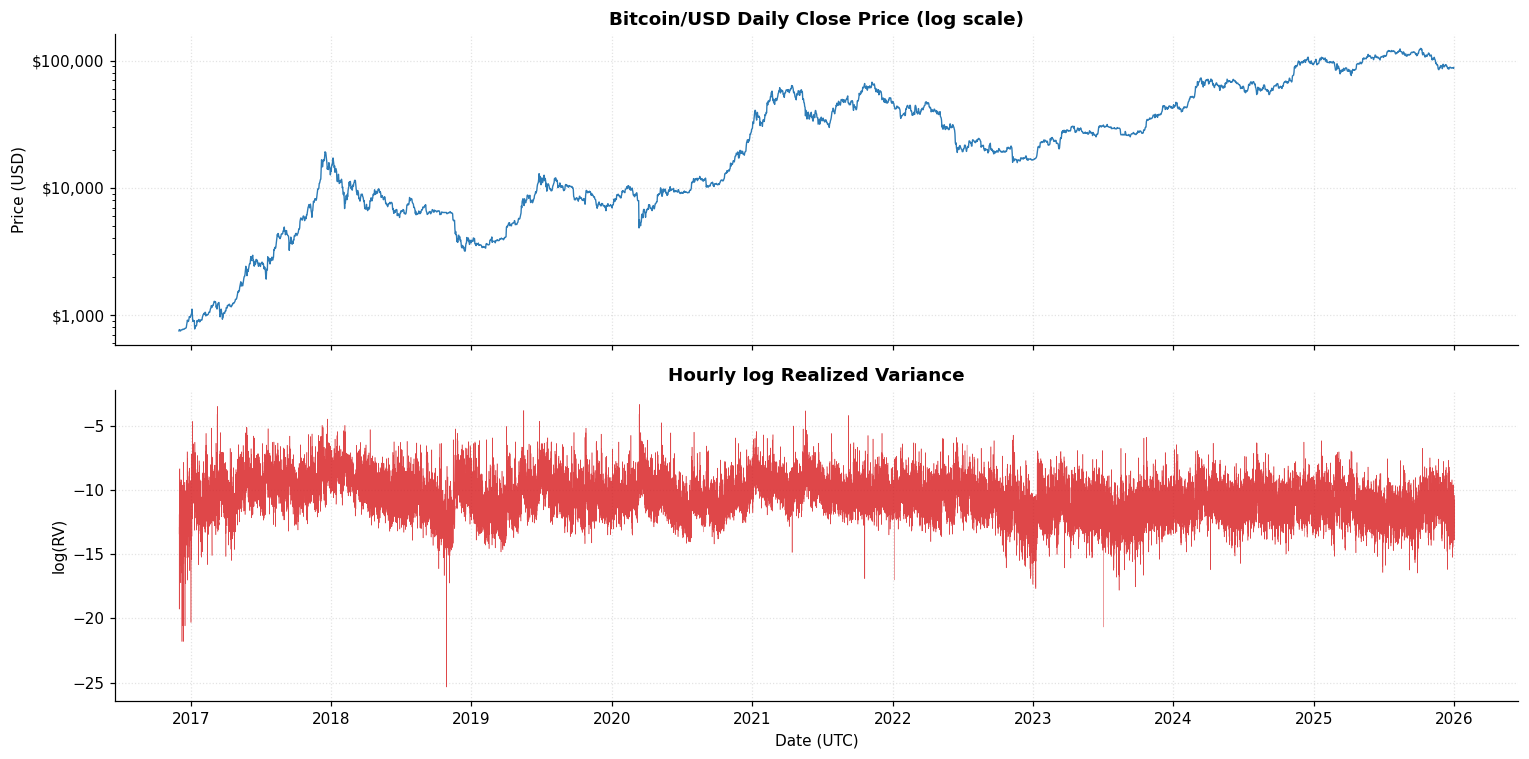

In [122]:
# Figure: Price + log_RV overview and Figure: Hourly Log Realized Variance

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
daily_px = raw["close"].resample("1D").last()

ax1.plot(daily_px.index, daily_px, color="#2C7BB6", lw=0.9)
ax1.set_yscale("log")
ax1.set_title("Bitcoin/USD Daily Close Price (log scale)",
              fontweight="bold")

ax1.set_ylabel("Price (USD)")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax2.plot(rv.index, rv["log_RV"], color="#D7191C", lw=0.35, alpha=0.8)
ax2.set_title("Hourly log Realized Variance",
              fontweight="bold")

ax2.set_ylabel("log(RV)")
ax2.set_xlabel("Date (UTC)")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_1_2.png", dpi=200)
plt.show()

In [123]:
# Descriptive statistics

def desc_stats(s, name):
    s = s.dropna()
    jb_stat, jb_p = jarque_bera(s)
    return pd.Series({
        "N": len(s), "Mean": s.mean(), "Std": s.std(),
        "Skew": skew(s), "Kurt(ex)": kurtosis(s),
        "Min": s.min(), "Max": s.max(),
        "JB stat": jb_stat, "JB p": jb_p,
    }, name=name)

stats = pd.concat([desc_stats(returns, "5-min returns"),
                   desc_stats(rv_ser, "Hourly RV"),
                   desc_stats(logrv, "Hourly log_RV")], axis=1)

print("\n  Descriptive Statistics:")
print("  " + "─" * 65)
print(stats.round(4).to_string())
jb_rv  = jarque_bera(rv_ser.dropna())
jb_log = jarque_bera(logrv.dropna())
print(f"\n  log transformation reduces JB by {jb_rv[0]/jb_log[0]:.2e}×")
print(" *Supports log_RV as modelling target (far less skewed and heavy-tailed than RV levels).")
stats.to_csv(f"{OUT_DIR}/table_descriptive_stats.csv")


  Descriptive Statistics:
  ─────────────────────────────────────────────────────────────────
          5-min returns     Hourly RV  Hourly log_RV
N          9.554040e+05  7.961700e+04     79606.0000
Mean       0.000000e+00  1.000000e-04       -10.7498
Std        2.400000e-03  3.000000e-04         1.4605
Skew      -6.116000e-01  5.122400e+01         0.0182
Kurt(ex)   8.233940e+01  4.433185e+03         0.8786
Min       -1.554000e-01  0.000000e+00       -25.3541
Max        8.180000e-02  3.660000e-02        -3.3067
JB stat    2.699525e+08  6.523162e+10      2564.6347
JB p       0.000000e+00  0.000000e+00         0.0000

  log transformation reduces JB by 2.54e+07×
 *Supports log_RV as modelling target (far less skewed and heavy-tailed than RV levels).


Bitcoin's realized variance exhibits a highly skewed and heavy-tailed distribution (see the skewness, excess kurtosis and Jarque–Bera statistics above): volatility remains low for extended periods, while extreme events generate very large spikes. This weakens the normality assumption underlying HAR and GARCH models, particularly during market stress.

A logarithmic transformation brings the series much closer to a normal distribution — skewness, excess kurtosis and the Jarque–Bera statistic all fall by orders of magnitude (compare the three columns above) — which supports `log_RV` as the modelling variable throughout this study.

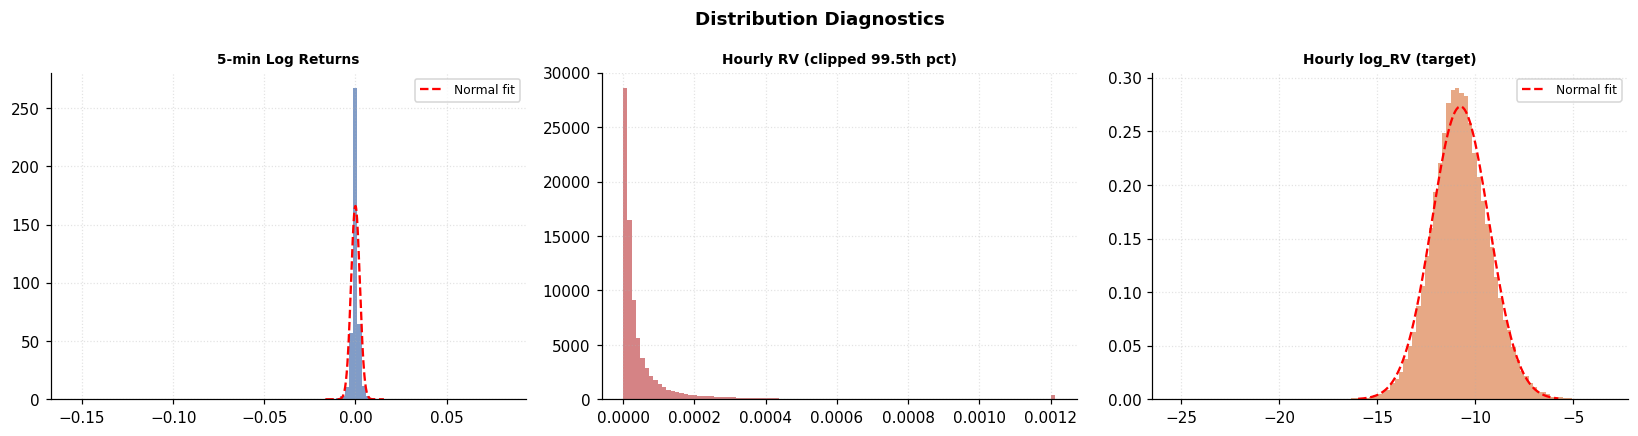

In [124]:
# Distribution diagnostics

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, ser, colour, title in [
    (axes[0], returns, "#4C72B0", "5-min Log Returns"),
    (axes[1], rv_ser.clip(upper=rv_ser.quantile(0.995)),
              "#C44E52", "Hourly RV (clipped 99.5th pct)"),
    (axes[2], logrv,   "#DD8452", "Hourly log_RV (target)"),
]:
    ax.hist(ser.dropna(), bins=100, density=True, color=colour, alpha=0.7)
    if title != "Hourly RV (clipped 99.5th pct)":
        xs = np.linspace(ser.dropna().quantile(0.001),
                         ser.dropna().quantile(0.999), 300)
        ax.plot(xs, _norm.pdf(xs, ser.mean(), ser.std()),
                "r--", lw=1.5, label="Normal fit")
        ax.legend(fontsize=8)
    ax.set_title(f"{title}", fontweight="bold", fontsize=9)

plt.suptitle("Distribution Diagnostics", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_3.png", dpi=200)
plt.show()

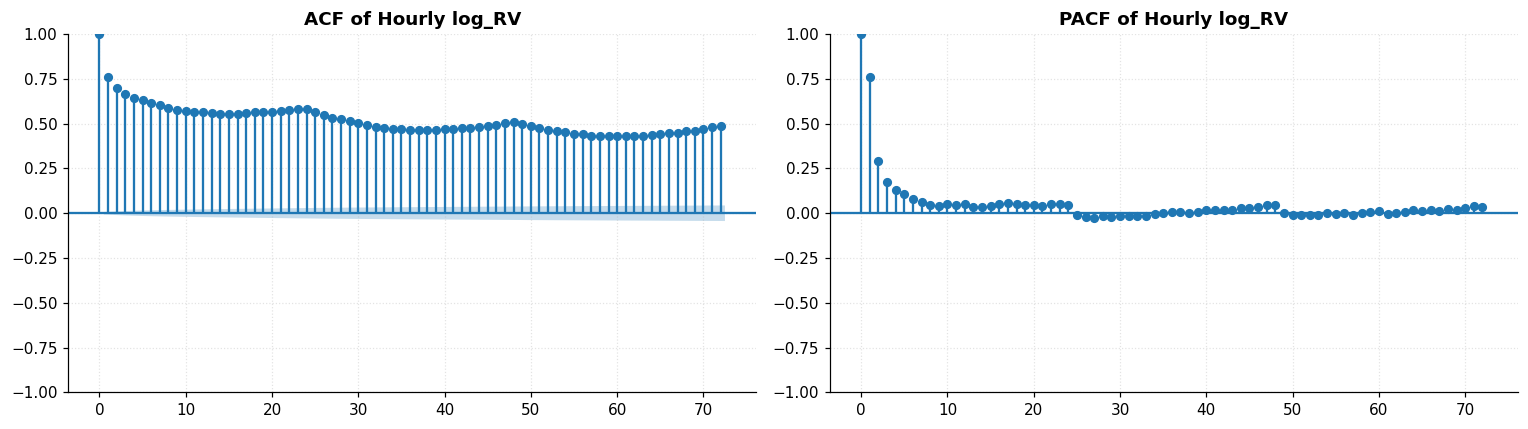

  ACF(1)=0.761  ACF(24)=0.584  ACF(72)=0.486 | PACF(1)=0.761  PACF(2)=0.289  PACF(3)=0.175


In [125]:
# ACF / PACF

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(logrv,  lags=72, alpha=0.05, ax=axes[0])
axes[0].set_title("ACF of Hourly log_RV", fontweight="bold")
plot_pacf(logrv, lags=72, method="ywm", alpha=0.05, ax=axes[1])
axes[1].set_title("PACF of Hourly log_RV", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_4.png", dpi=200)
plt.show()

from statsmodels.tsa.stattools import acf as _acf, pacf as _pacf
_a = _acf(logrv, nlags=72, fft=True); _p = _pacf(logrv, nlags=72, method="ywm")
print(f"  ACF(1)={_a[1]:.3f}  ACF(24)={_a[24]:.3f}  ACF(72)={_a[72]:.3f} | "
      f"PACF(1)={_p[1]:.3f}  PACF(2)={_p[2]:.3f}  PACF(3)={_p[3]:.3f}")

- ##### ACF (Autocorrelation Function)

The ACF shows how strongly a series is correlated with its own past values. A slow decline over many lags (the values printed above) indicates strong persistence: when volatility becomes high, it tends to stay high for a long period rather than returning immediately to normal levels — a typical sign of long memory in volatility.

- ##### PACF (Partial Autocorrelation Function)

The PACF measures the direct relationship between the current value and a past value after removing the effects of the intermediate lags. The ACF indicates substantial persistence, while the PACF shows where the strongest direct linear dependence lies (read from the printed values). These diagnostics motivate multi-horizon predictors but are not a formal test of fractional long memory.

In [126]:
# Stationarity & ARCH

adf = adfuller(logrv.dropna(), autolag="AIC")
print(f"\n  ADF test (log_RV): stat={adf[0]:.4f}  p={adf[1]:.4g}  "
      f"→ {'stationary' if adf[1] < 0.05 else 'non-stationary'}")

arch_test = het_arch(hourly_ret.dropna(), nlags=24)
print(f"  ARCH LM (24 lags): stat={arch_test[0]:.4f}  p={arch_test[1]:.4g}  "
      f" ARCH effects {'present' if arch_test[1] < 0.05 else 'absent'}")


  ADF test (log_RV): stat=-13.2570  p=8.547e-25  → stationary
  ARCH LM (24 lags): stat=9550.0460  p=0   ARCH effects present


##### ADF Test — is log_RV stationary?

The null hypothesis of a unit root is tested on `log_RV`; rejection provides evidence against a unit root over the full sample. It does not rule out structural breaks, regime-dependent means or other forms of non-stationarity; it supports modelling log RV without first differencing. The statistic and p-value are printed above.

##### ARCH LM Test — does volatility cluster?

The ARCH-LM test is applied to the hourly return series. Rejection of the null of constant conditional variance indicates volatility clustering, the core motivation for the MC-GARCH model. The statistic and p-value are printed above.

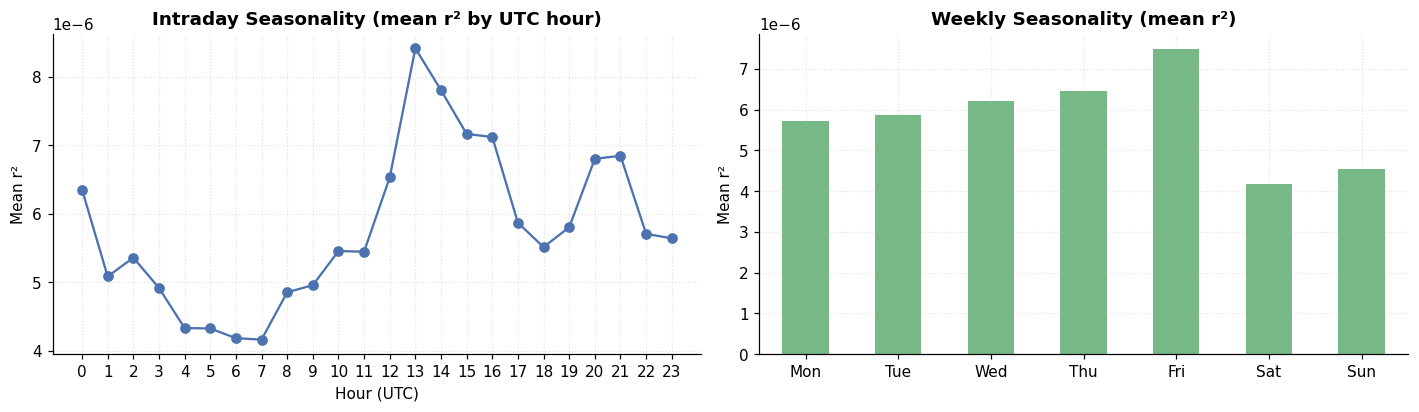

  Intraday: minimum at 07:00 UTC (4.164e-06), maximum at 13:00 UTC (8.414e-06), max/min = 2.02
  Weekday means: {'Mon': '5.724e-06', 'Tue': '5.858e-06', 'Wed': '6.214e-06', 'Thu': '6.450e-06', 'Fri': '7.486e-06', 'Sat': '4.181e-06', 'Sun': '4.532e-06'}
  Highest weekday: Fri | lowest weekday: Sat


In [127]:
# Intraday / weekly seasonality

intra = raw[["r2_5m"]].dropna().copy()
intra["hour_utc"] = intra.index.hour
intra["weekday"]  = intra.index.dayofweek
h_prof = intra.groupby("hour_utc")["r2_5m"].mean()
d_prof = intra.groupby("weekday")["r2_5m"].mean()
d_prof.index = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
h_prof.plot(marker="o", color="#4C72B0", lw=1.5, ax=axes[0])
axes[0].set_title("Intraday Seasonality (mean r² by UTC hour)",
                  fontweight="bold")

axes[0].set_xlabel("Hour (UTC)"); axes[0].set_ylabel("Mean r²")
axes[0].set_xticks(range(24))
d_prof.plot(kind="bar", color="#55A868", alpha=0.8, rot=0, ax=axes[1])
axes[1].set_title("Weekly Seasonality (mean r²)", fontweight="bold")
axes[1].set_ylabel("Mean r²")

plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_5.png", dpi=200)
plt.show()

print(f"  Intraday: minimum at {h_prof.idxmin():02d}:00 UTC ({h_prof.min():.3e}), "
      f"maximum at {h_prof.idxmax():02d}:00 UTC ({h_prof.max():.3e}), max/min = {h_prof.max()/h_prof.min():.2f}")
print("  Weekday means:", {k: f"{v:.3e}" for k, v in d_prof.items()})
print(f"  Highest weekday: {d_prof.idxmax()} | lowest weekday: {d_prof.idxmin()}")

- ##### Intraday Pattern

Bitcoin volatility follows a distinct daily cycle. The hour of minimum and maximum mean squared return, and their ratio, are printed in the cell above (the hour label is the UTC clock hour containing the 5-minute interval).

- ##### Weekly Pattern

The same cell prints the mean squared return by weekday and identifies the most and least volatile day.

- ##### Implications for Modelling

These recurring patterns motivate testing calendar features as potential predictors; seasonality in the data does not by itself guarantee out-of-sample improvement. To capture these cyclical behaviours, the LSTM model includes time-based features: `hour_sin`/`hour_cos` (intraday cycle) and `dow_sin`/`dow_cos` (weekly cycle). The MC-GARCH model handles the intraday cycle through its hour-of-day factor.

## 3 — FEATURE ENGINEERING (MODEL-SPECIFIC)

In [128]:
EPS = 1e-12   # numerical floor for log transforms — prevents log(0) errors
df  = rv[["RV", "log_RV", "jump", "RS_minus", "prev_RV", "eval_ok"]].copy()

All features are constructed from the hourly RV series computed in Section 1. Three nested feature sets are built in sequence — {HAR-Classic, HAR-Extended, and LSTM} — each adding variables to the previous set. Every feature uses only past information (`shift(1)` before any rolling window), so no look-ahead bias is introduced. The hourly time axis is kept **continuous**: rows are never dropped, because dropping rows would break the contiguity of the LSTM's 168-hour windows. Rows that cannot be used are flagged instead (`feat_ok`, `use`).

In [129]:
#  3.1 HAR lags

# Corsi (2009) log-linear HAR: regress log(RV_t) on log(RV_{t-k}).
# First: compute LEVEL rolling means from t-1 backward (no leakage).
# Second: take log — this ensures the predictor and target share the same scale.

df["RV_1h"] = df["RV"].shift(1)
df["RV_24h"] = df["RV"].shift(1).rolling(24).mean()
df["RV_168h"] = df["RV"].shift(1).rolling(168).mean()

# 1h lag: for the hour after a zero-RV hour log(0) is undefined. Carry the last valid value forward
# (such rows have eval_ok = False and are never targets; carrying keeps the LSTM input window contiguous).
df["log_RV_1h"] = np.log(df["RV_1h"].where(df["RV_1h"] > 0)).ffill()
df["log_RV_24h"] = np.log(df["RV_24h"].clip(lower=EPS))
df["log_RV_168h"] = np.log(df["RV_168h"].clip(lower=EPS))

The three HAR components are constructed as log-averages of past realized variance at the hourly (1h), daily (24h), and weekly (168h) horizons:

$$\text{log\_RV\_1h}_t   = \log\, RV_{t-1}$$
$$\text{log\_RV\_24h}_t  = \log\!\left(\frac{1}{24}\sum_{k=1}^{24} RV_{t-k}\right)$$
$$\text{log\_RV\_168h}_t = \log\!\left(\frac{1}{168}\sum_{k=1}^{168} RV_{t-k}\right)$$

`shift(1)` is applied before every rolling window — the window looks backward from $t-1$, never touching $t$. In the 24h and 168h averages a zero-RV hour simply contributes zero to the mean. In the 1h lag, the hour that follows a zero-RV hour would require $\log 0$; there the last positive-RV lag is carried forward (a causal imputation: only past information is used). Those rows are excluded as targets (`eval_ok = False`), but the imputed value may still enter later LSTM input windows. This preserves sequence continuity without using future information.

In [130]:
#  3.2 Jump ratio — daily (Andersen et al. 2007)

# Proportion of total 24h variance attributable to discontinuous price jumps.
# Bounded in [0, 1] by construction; filled with 0 when RV sum is zero.

rv24_roll = df["RV"].shift(1).rolling(24).sum().replace(0, np.nan)

df["jump_24h"] = (df["jump"].shift(1).rolling(24).sum() / rv24_roll).fillna(0.0).clip(0, 1)

$$\text{jump\_24h}_t = \frac{\sum_{k=1}^{24} J_{t-k}}{\sum_{k=1}^{24} RV_{t-k}}, \qquad J_t = \max(RV_t - BPV_t,\ 0)$$

A value close to 1 indicates that most of the past day's variance came from discontinuous price jumps; a value close to 0 indicates smooth, diffusive variation. Filled with 0 when the denominator is zero (no trading activity).

In [131]:
#  3.3 Downside semivariance ratio — daily (Patton & Sheppard 2015)

# Proportion of total 24h variance attributable to negative returns.
# Bounded in [0, 1]; filled with 0.5 (symmetric prior) when RV sum is zero.

df["RS_minus_24h"] = (df["RS_minus"].shift(1).rolling(24).sum() / rv24_roll).fillna(0.5).clip(0, 1)

$$\text{RS\_minus\_24h}_t = \frac{\sum_{k=1}^{24} RS^-_{t-k}}{\sum_{k=1}^{24} RV_{t-k}}$$

Captures the asymmetric contribution of negative returns to total variance. If downside volatility is systematically higher than upside volatility, this ratio exceeds 0.5. The neutral prior of 0.5 is used as a fill value when the denominator is zero.

In [132]:
#  3.4 Calendar features — cyclical encoding for only LSTM

# Sine/cosine encoding preserves the circular nature of time:
# hour 23 and hour 0 are adjacent in this representation.
# Integer labels (0–23, 0–6) would impose an artificial ordinal distance.

df["hour_sin"] = np.sin(2 * np.pi * df.index.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df.index.hour / 24)
df["dow_sin"] = np.sin(2 * np.pi * df.index.dayofweek / 7)
df["dow_cos"] = np.cos(2 * np.pi * df.index.dayofweek / 7)

Hours and weekdays are encoded as sine/cosine pairs:

$$\text{hour\_sin}_t = \sin\!\left(\frac{2\pi \cdot h_t}{24}\right), \quad
  \text{hour\_cos}_t = \cos\!\left(\frac{2\pi \cdot h_t}{24}\right)$$

$$\text{dow\_sin}_t  = \sin\!\left(\frac{2\pi \cdot d_t}{7}\right),  \quad
  \text{dow\_cos}_t  = \cos\!\left(\frac{2\pi \cdot d_t}{7}\right)$$

where $h_t \in \{0,\ldots,23\}$ and $d_t \in \{0,\ldots,6\}$. These four features are included only in the LSTM specification.

In [133]:
#  3.5 Clean up and flag usable rows (the hourly axis stays continuous: NO rows are dropped)

df = df.drop(columns=["jump", "RS_minus", "RV_1h", "RV_24h", "RV_168h"])

# feat_ok : all LSTM features are defined (first 168 rows are warm-up for the longest rolling window)
# use     : the row may serve as a forecast target / evaluation hour for EVERY model
df["feat_ok"] = df[LSTM_FEATS].notna().all(axis=1)
df["use"] = df["eval_ok"] & df["feat_ok"]

print(f"\n  Feature frame      : {df.shape[0]:,} hourly rows × {df.shape[1]} columns (continuous axis)")
print(f"  Warm-up rows       : {int((~df['feat_ok']).sum())}  (longest rolling window = 168h)")
print(f"  First feature hour : {df.index[df['feat_ok']][0]}")
print(f"  Usable target rows : {int(df['use'].sum()):,}")
print(f"  Columns            : {list(df.columns)}")
assert np.isfinite(df.loc[df["feat_ok"], LSTM_FEATS].to_numpy()).all(), "NaN/inf in features"
assert (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "Hourly axis lost continuity"

# Leakage check: features at hour t must be built from hours < t only.
_rng = np.random.default_rng(RANDOM_SEED)
_pos = _rng.choice(np.arange(200, len(df)), size=3000, replace=False)
_RV = df["RV"].to_numpy()
for p in _pos:
    assert np.isclose(df["log_RV_24h"].iloc[p], np.log(max(_RV[p-24:p].mean(), EPS)))
    assert np.isclose(df["log_RV_168h"].iloc[p], np.log(max(_RV[p-168:p].mean(), EPS)))
    if _RV[p-1] > 0:
        assert np.isclose(df["log_RV_1h"].iloc[p], np.log(_RV[p-1]))
print("  Leakage check passed: all HAR lags use only hours strictly before t (3,000 random hours)")


  Feature frame      : 79,617 hourly rows × 15 columns (continuous axis)
  Warm-up rows       : 168  (longest rolling window = 168h)
  First feature hour : 2016-12-08 15:00:00+00:00
  Usable target rows : 79,431
  Columns            : ['RV', 'log_RV', 'prev_RV', 'eval_ok', 'log_RV_1h', 'log_RV_24h', 'log_RV_168h', 'jump_24h', 'RS_minus_24h', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'feat_ok', 'use']
  Leakage check passed: all HAR lags use only hours strictly before t (3,000 random hours)


In [134]:
#  3.6 Feature–target correlations

# Pearson r: linear association. Spearman ρ: monotonic association.
# Both reported; large divergence would indicate strong nonlinearity.

fe = df[df["use"]]                      # rows a model may use (same rows for every statistic below)

print(f"\n  Feature–Target Correlations (vs log_RV, n={len(fe):,}):")
print(f"  {'Feature':<18} {'Pearson r':>10} {'Spearman ρ':>12}")
print("  " + "─" * 42)
for col in ALL_FEATS:
    rp, _ = pearsonr(fe[col], fe["log_RV"])
    rs, _ = spearmanr(fe[col], fe["log_RV"])
    print(f"  {col:<18} {rp:>10.4f} {rs:>12.4f}")


  Feature–Target Correlations (vs log_RV, n=79,431):
  Feature             Pearson r   Spearman ρ
  ──────────────────────────────────────────
  log_RV_1h              0.7623       0.7503
  log_RV_24h             0.7352       0.7192
  log_RV_168h            0.6650       0.6573
  jump_24h              -0.0275      -0.0055
  RS_minus_24h           0.0376       0.0417
  hour_sin              -0.1312      -0.1286
  hour_cos              -0.0418      -0.0486
  dow_sin                0.1411       0.1362
  dow_cos               -0.0329       0.0004


Pearson r and Spearman ρ are reported jointly. When both are similar the relationship is approximately linear; a large divergence would indicate nonlinearity or outlier sensitivity.

How to read the table above:

- **HAR lags** (`log_RV_1h/24h/168h`): strong correlations that decline with horizon length — the empirical signature of volatility persistence that motivates the HAR multi-horizon structure.
- **`jump_24h`, `RS_minus_24h`**: if the correlations are close to zero, these features carry little linear information about the target, which anticipates a small contribution of HAR-Extended over HAR-Classic. The formal test is in Section 10.
- **Calendar features**: weak linear association is expected, because their effect is cyclical and nonlinear.

In [135]:
#  3.7 Variance Inflation Factors (*multicollinearity check*)

# VIF_j = 1 / (1 - R²_j), where R²_j is the R² from regressing feature j on all other features.
# The auxiliary regressions need an INTERCEPT: without a constant column they run through the origin, which
# inflates R² for variables whose mean is far from zero (log RV averages about -10) and hence inflates the VIFs.
# Calendar features are orthogonal by construction (sin/cos pairs), so only the HAR + Extended features are checked.

vif_cols = HAR_CLASSIC_FEATS + ["jump_24h", "RS_minus_24h"]
X_vif = sm.add_constant(fe[vif_cols]).values
vif = pd.DataFrame({
    "Feature": vif_cols,
    "VIF": [variance_inflation_factor(X_vif, i) for i in range(1, X_vif.shape[1])]   # skip the constant
})

print("\n  Variance Inflation Factors (design matrix with constant):")
print("  " + "─" * 30)
print(vif.to_string(index=False))
print("\n  Rule of thumb: VIF > 10  >>> severe multicollinearity")
print(" VIF 5–10  >>> moderate multicollinearity")
print(" VIF < 5  >>> acceptable")
vif.to_csv(f"{OUT_DIR}/table_vif.csv", index=False)


  Variance Inflation Factors (design matrix with constant):
  ──────────────────────────────
     Feature      VIF
   log_RV_1h 2.456656
  log_RV_24h 4.264768
 log_RV_168h 3.193161
    jump_24h 1.010585
RS_minus_24h 1.005979

  Rule of thumb: VIF > 10  >>> severe multicollinearity
 VIF 5–10  >>> moderate multicollinearity
 VIF < 5  >>> acceptable


The three HAR lags are overlapping rolling averages of the same series (`log_RV_24h` contains the 24 values of which `log_RV_1h` is one; `log_RV_168h` contains all values of `log_RV_24h`), so a degree of mechanical collinearity is unavoidable. The VIFs above are computed with an intercept in the auxiliary regressions, as required.

The HAR model is used here for **prediction**, not for structural interpretation of individual coefficients. Multicollinearity inflates coefficient uncertainty and complicates the interpretation of individual coefficients; it does not by itself bias the OLS coefficients, and its out-of-sample effect is assessed empirically through RMSE, QLIKE and the Diebold–Mariano test. This is the standard stance in the HAR literature (Corsi, 2009).

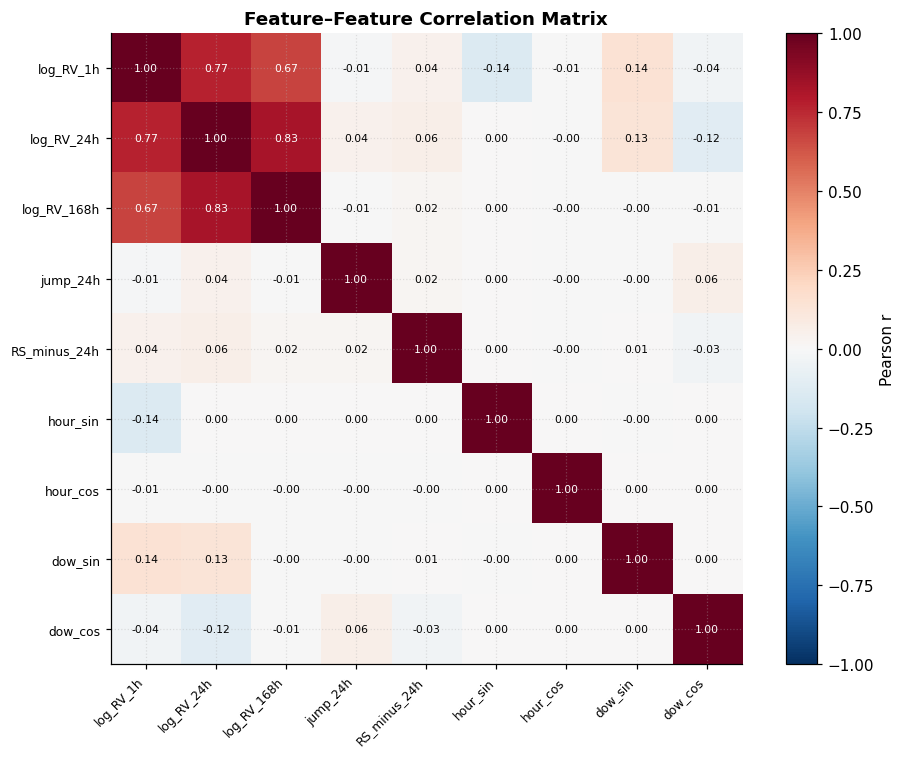

In [136]:
#  3.8 Feature–feature correlation heatmap

fig, ax = plt.subplots(figsize=(9, 7))
corr_matrix = fe[ALL_FEATS].corr()
im = ax.imshow(corr_matrix.values, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, label="Pearson r")
ax.set_xticks(range(len(ALL_FEATS)))
ax.set_xticklabels(ALL_FEATS, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(ALL_FEATS)))
ax.set_yticklabels(ALL_FEATS, fontsize=8)
for i in range(len(ALL_FEATS)):
    for j in range(len(ALL_FEATS)):
        v = corr_matrix.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                fontsize=7, color="white" if abs(v) > 0.6 else "black")

ax.set_title("Feature–Feature Correlation Matrix", fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_6.png", dpi=200)
plt.show()

In [137]:
print("\n  Feature–Feature Correlation Matrix:")
print("  " + "─" * (18 * len(ALL_FEATS) + 4))
header = f"  {'':18}" + "".join(f"{c:>10}" for c in ALL_FEATS)
print(header)
print("  " + "─" * len(header))
for row_feat in ALL_FEATS:
    row = f"  {row_feat:<18}"
    for col_feat in ALL_FEATS:
        v = corr_matrix.loc[row_feat, col_feat]
        row += f"{v:>10.3f}"
    print(row)


  Feature–Feature Correlation Matrix:
  ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
                     log_RV_1hlog_RV_24hlog_RV_168h  jump_24hRS_minus_24h  hour_sin  hour_cos   dow_sin   dow_cos
  ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
  log_RV_1h              1.000     0.766     0.672    -0.010     0.044    -0.138    -0.007     0.142    -0.036
  log_RV_24h             0.766     1.000     0.825     0.041     0.056     0.001    -0.004     0.131    -0.116
  log_RV_168h            0.672     0.825     1.000    -0.007     0.017     0.000    -0.000    -0.003    -0.005
  jump_24h              -0.010     0.041    -0.007     1.000     0.018     0.003    -0.002    -0.000     0.060
  RS_minus_24h           0.044     0.056     0.017     0.018     1.000     0.001    -0.001     0.008    -0.033
  hour_

- **HAR lags:** pairwise correlations are high by construction (overlapping rolling averages); this is the source of the VIF values in Section 3.7.
- **Calendar features:** sine/cosine pairs encoding different cycles are orthogonal by construction, so their cross-correlations are effectively zero — the principal advantage of cyclical encoding over integer labels.
- **HAR lags vs. calendar features:** any non-negligible off-block correlation reflects the intraday seasonality documented in Section 2 — a genuine market-structure signal rather than a multicollinearity concern.
- **`jump_24h` and `RS_minus_24h`:** their correlations with the other features are shown in the matrix above.

## 4 — TRAIN / VAL / TEST SPLIT

In [138]:
is_train = (df.index <= TRAIN_END)
is_val   = (df.index > TRAIN_END) & (df.index <= VAL_END)
is_test  = (df.index > VAL_END)

train, val, test = df[is_train], df[is_val], df[is_test]

assert train.index.max() < val.index.min(),  "Train/Val overlap"
assert val.index.max()   < test.index.min(), "Val/Test overlap"
assert len(val) == 17520 and len(test) == 17544

print(f"\n  {'Split':<12} {'Period':<26} {'Hours':>8} {'Usable targets':>15}  {'%':>5}")
print("  " + "─" * 72)
n_use = int(df["use"].sum())
for name, s, period in [
    ("Train", train, f"{train.index.min().date()} → {train.index.max().date()}"),
    ("Validation", val,   f"{val.index.min().date()} → {val.index.max().date()}"),
    ("Test", test,  f"{test.index.min().date()} → {test.index.max().date()}"),
]:
    print(f"  {name:<12} {period:<26} {len(s):>8,} {int(s['use'].sum()):>15,}  {s['use'].sum()/n_use*100:>5.1f}%")

# Shared evaluation timestamps: EVERY model is evaluated on exactly these hours
test_index = df.index[df["use"] & is_test]
y_true_log = df.loc[test_index, "log_RV"].values
assert len(test_index) == EXPECTED_TEST_EVAL, f"Unexpected number of test targets: {len(test_index)}"

# Calendar-defined walk-forward folds (identical to the R script)
val_hours = df.index[is_val]
_chunk = len(val_hours) // WFV_N_SPLITS
assert _chunk * WFV_N_SPLITS == len(val_hours) and _chunk == 3504
FOLDS = []
for _k in range(WFV_N_SPLITS):
    _s, _e = val_hours[_k * _chunk], val_hours[(_k + 1) * _chunk - 1]
    _ev = df.index[df["use"] & (df.index >= _s) & (df.index <= _e)]
    FOLDS.append({"fold": _k + 1, "start": _s, "end": _e, "eval_idx": _ev})
assert [len(f["eval_idx"]) for f in FOLDS] == EXPECTED_WFV_EVAL, [len(f["eval_idx"]) for f in FOLDS]
print("\n  Walk-forward folds (validation period, expanding training window):")
for f in FOLDS:
    print(f"   Fold {f['fold']}: {f['start']} → {f['end']} | evaluated hours: {len(f['eval_idx'])}")


  Split        Period                        Hours  Usable targets      %
  ────────────────────────────────────────────────────────────────────────
  Train        2016-12-01 → 2021-12-31      44,553          44,378   55.9%
  Validation   2022-01-01 → 2023-12-31      17,520          17,514   22.0%
  Test         2024-01-01 → 2025-12-31      17,544          17,539   22.1%

  Walk-forward folds (validation period, expanding training window):
   Fold 1: 2022-01-01 00:00:00+00:00 → 2022-05-26 23:00:00+00:00 | evaluated hours: 3502
   Fold 2: 2022-05-27 00:00:00+00:00 → 2022-10-19 23:00:00+00:00 | evaluated hours: 3502
   Fold 3: 2022-10-20 00:00:00+00:00 → 2023-03-14 23:00:00+00:00 | evaluated hours: 3504
   Fold 4: 2023-03-15 00:00:00+00:00 → 2023-08-07 23:00:00+00:00 | evaluated hours: 3502
   Fold 5: 2023-08-08 00:00:00+00:00 → 2023-12-31 23:00:00+00:00 | evaluated hours: 3504


**Train (2016-12-01 → 2021-12-31):** Five years covering Bitcoin's early regime spectrum — the 2017 bull run, the 2018 bear market, the COVID crash and recovery, and the 2021 all-time high. The HAR/LSTM feature matrix is defined from 2016-12-08 15:00 onwards because the 168-hour lag requires one week of warm-up; MC-GARCH, which needs only the previous day, is estimated from 2016-12-01 15:00 onwards.

**Validation (2022-01-01 → 2023-12-31):** the two years used for walk-forward validation. They contain the LUNA/Terra collapse (May 2022), the FTX bankruptcy (November 2022) and the bear market that followed. Validation results describe performance *within this stressed regime*.

**Test (2024-01-01 → 2025-12-31):** a structurally distinct out-of-sample period. Models never see these data during training or validation. The regime difference between the validation window and the test window is quantified in Section 10 (mean log RV by period) and must be taken into account when comparing validation and test numbers.

Every model is evaluated on the same **usable target hours** (`use`): hours with $RV_t>0$, $RV_{t-1}>0$ and fully defined features. Validation and test hours are never lost to LSTM sequence construction (Section 9).

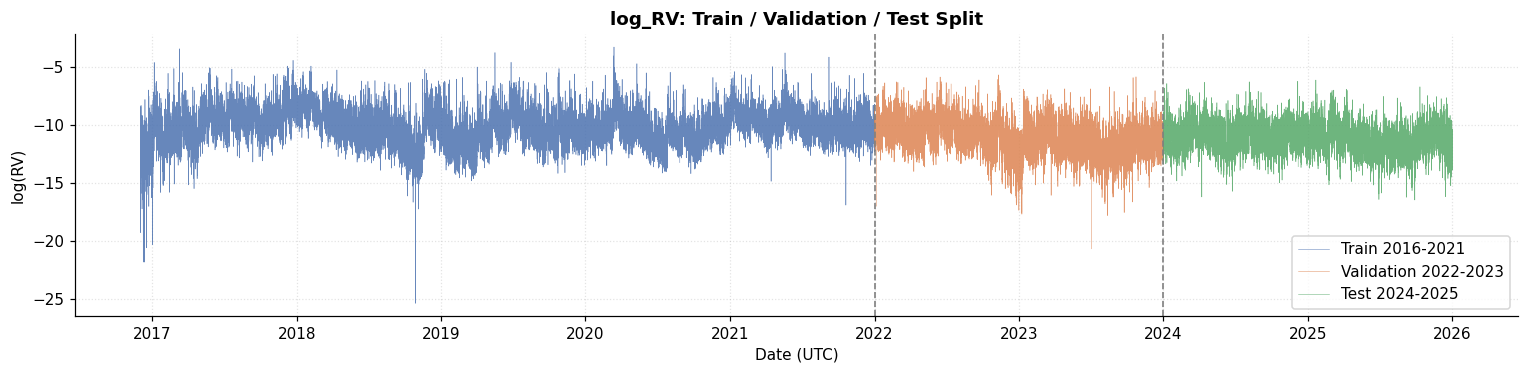

In [139]:
# Split visualisation
fig, ax = plt.subplots(figsize=(14, 3.5))
for s, colour, lbl in [
    (train, "#4C72B0", "Train 2016-2021"),
    (val,   "#DD8452", "Validation 2022-2023"),
    (test,  "#55A868", "Test 2024-2025"),
]:
    ax.plot(s.index, s["log_RV"], color=colour, lw=0.35, alpha=0.85, label=lbl)
ax.axvline(TRAIN_END, color="gray", lw=1.1, ls="--")
ax.axvline(VAL_END,   color="gray", lw=1.1, ls="--")
ax.set_title("log_RV: Train / Validation / Test Split",
             fontweight="bold")

ax.set_ylabel("log(RV)"); ax.set_xlabel("Date (UTC)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/figure_7.png", dpi=200)
plt.show()

## 5 — EVALUATION & UTILITY FUNCTIONS

In [140]:
# QLIKE floor: numerical guard against near-zero predicted variance (Patton 2011). Set to the 0.1th percentile of positive
# training RV so that log(0) or division by zero cannot occur, without materially affecting well-calibrated forecasts.

QLIKE_FLOOR = float(train.loc[train["RV"] > 0, "RV"].quantile(0.001))
print(f"QLIKE floor = {QLIKE_FLOOR:.3e}")

QLIKE floor = 2.459e-07


A small numerical floor is applied to the predicted RV before computing QLIKE (Patton 2011). It prevents division by zero when a model produces a near-zero forecast, without meaningfully affecting the loss of any well-calibrated forecast. The floor is computed from training data only and is applied identically to every model, to the validation folds and to the test set.

In [141]:
def qlike_vec(rv_true, rv_pred):
    """
    Observation-wise QLIKE loss in RV space (Patton 2011):  L_t = r_t - log(r_t) - 1,  r_t = RV_t / RV_hat_t.

    Expressed through the actual-to-forecast ratio; particularly sensitive to forecasts that are too small relative to realised variance.
    The mean of this vector is the QLIKE metric; the vector itself is the loss series used in the DM tests.
    """
    rp = np.maximum(np.asarray(rv_pred, float), QLIKE_FLOOR)
    r = np.asarray(rv_true, float) / rp
    return r - np.log(r) - 1.0


def metrics(y_true_log, y_pred_log):
    """
    One metric definition for every model and every evaluation period.

    Forecast error e = actual - forecast on the log_RV scale, so Bias = mean(e):
    positive Bias means the model under-predicts on average.
    The RV-scale forecast is exp(log_RV_hat) (median forecast of a log-normal model) for ALL models.
    """
    yt = np.asarray(y_true_log, float)
    yp = np.asarray(y_pred_log, float)
    e = yt - yp
    rv_t, rv_p = np.exp(yt), np.exp(yp)
    return {
        "RMSE": float(np.sqrt(np.mean(e ** 2))),
        "MAE": float(np.mean(np.abs(e))),
        "Bias": float(np.mean(e)),
        "R2": float(1.0 - np.sum(e ** 2) / np.sum((yt - yt.mean()) ** 2)),
        "QLIKE": float(np.mean(qlike_vec(rv_t, rv_p))),
        "RV_RMSE": float(np.sqrt(np.mean((rv_t - rv_p) ** 2))),
        "N": int(len(yt)),
    }

`metrics` evaluates every model on two scales with one definition. On the **log_RV scale**: RMSE, MAE, Bias (mean of actual − forecast, so a positive value means under-prediction) and R². On the **RV scale**: the back-transformed forecast $\widehat{RV}_t=\exp(\widehat{\log RV}_t)$ is used for QLIKE and RV-RMSE. No Jensen correction is applied, and the same formula is used for all models, so numbers are comparable across models, across validation and test, and with the R script.

R² is computed relative to the mean of the evaluation sample (it can be negative for a model worse than a horizontal line). Mincer–Zarnowitz regressions are deliberately **not** used anywhere in this study.

In [142]:
# Evaluation sets (identical hours for every model)

# TEST   : test_index (17,539 hours)                                  -> held-out results
# VALID. : val_index = the five walk-forward folds pooled (17,514)    -> model-development results
val_index = df.index[df["use"] & is_val]
val_fold = np.concatenate([np.full(len(f["eval_idx"]), f["fold"]) for f in FOLDS])
assert val_index.equals(FOLDS[0]["eval_idx"].append([f["eval_idx"] for f in FOLDS[1:]])), "Fold union differs from the validation target set"

y_val_log = df.loc[val_index, "log_RV"].values
y_test_log = y_true_log                                  # from Section 4
pos_of = lambda idx: df.index.get_indexer(idx)           # integer positions on the continuous hourly axis

PRED = {"val": {}, "test": {}}                           # PRED[period][model] -> forecast array aligned with val_index / test_index

def register(name, val_pred, test_pred):
    val_pred, test_pred = np.asarray(val_pred, float), np.asarray(test_pred, float)
    assert val_pred.shape == y_val_log.shape and test_pred.shape == y_test_log.shape, f"{name}: wrong length"
    assert np.isfinite(val_pred).all() and np.isfinite(test_pred).all(), f"{name}: non-finite forecasts"
    PRED["val"][name], PRED["test"][name] = val_pred, test_pred

def report(name):
    """Print one compact validation/test line pair for a registered model."""
    for per, y in [("val", y_val_log), ("test", y_test_log)]:
        m = metrics(y, PRED[per][name])
        tag = "VALIDATION (pooled WFV)" if per == "val" else "TEST (held-out)"
        print(f"  {name:<16} {tag:<24} RMSE={m['RMSE']:.4f}  MAE={m['MAE']:.4f}  Bias={m['Bias']:+.4f}  "
              f"R2={m['R2']:.4f}  QLIKE={m['QLIKE']:.4f}  (n={m['N']:,})")

def fold_table(name):
    """Per-fold validation metrics of one model."""
    rows = []
    for f in FOLDS:
        msk = val_fold == f["fold"]
        m = metrics(y_val_log[msk], PRED["val"][name][msk])
        m["fold"] = f["fold"]; m["period"] = f"{f['start'].date()}→{f['end'].date()}"
        rows.append(m)
    return pd.DataFrame(rows).set_index("fold")[["period", "N", "RMSE", "MAE", "Bias", "QLIKE"]]

In [143]:
def plot_forecast_vs_actual(idx, y_true, y_pred, model_name, colour):
    """Forecast vs actual log_RV and forecast errors — side-by-side panel (test period)."""
    resid = y_true - y_pred
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(idx, y_true, color="#999999", lw=0.4, alpha=0.7, label="Actual log_RV")
    axes[0].plot(idx, y_pred, color=colour, lw=0.8, alpha=0.9, label=f"{model_name} forecast")
    axes[0].set_title(f"{model_name}: Forecast vs Actual (Test Period, 2024-2025)", fontweight="bold")
    axes[0].set_ylabel("log(RV)"); axes[0].legend(fontsize=8)
    axes[1].plot(idx, resid, color=colour, lw=0.4, alpha=0.7)
    axes[1].axhline(0, color="black", lw=0.8, ls="--")
    axes[1].set_title(f"{model_name}: Forecast errors (actual − forecast)", fontweight="bold")
    axes[1].set_ylabel("Error")
    plt.tight_layout(); plt.show()


def plot_error_dist(resid, model_name, colour):
    """Error histogram with normal overlay and QQ-plot."""
    from scipy.stats import probplot
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(resid, bins=60, density=True, color=colour, alpha=0.7)
    xs = np.linspace(resid.min(), resid.max(), 300)
    axes[0].plot(xs, _norm.pdf(xs, resid.mean(), resid.std()), "r--", lw=1.5, label="Normal fit")
    axes[0].axvline(0, color="black", lw=0.8)
    axes[0].set_title(f"{model_name}: Error Distribution", fontweight="bold"); axes[0].legend(fontsize=8)
    probplot(resid, plot=axes[1])
    axes[1].set_title(f"{model_name}: Error QQ-Plot", fontweight="bold")
    plt.tight_layout(); plt.show()

Two plotting helpers used by Sections 6–9. Walk-forward validation is the model-development evidence and the held-out test period is the final out-of-sample evidence; the two are always reported **separately and labelled**. No automatic "overfitting" classification is produced anywhere: a train-versus-test gap mixes overfitting with a change of volatility regime (Section 4), so generalisation is judged from the validation and test metrics themselves and from the DM tests in Section 10.

## 6 — NAIVE BENCHMARKS

Two reference forecasts. **Random Walk**: $\widehat{\log RV}_t=\log RV_{t-1}$ (always defined on the evaluation hours, because $RV_{t-1}>0$ there). **Historical Mean**: the expanding-window mean of `log_RV` over all usable hours *before* the evaluation block — i.e. before each validation fold, and before the test period for the test forecast (train + validation history). Neither has parameters to tune, so both are produced for validation and for test with the same rule as the fitted models.

In [144]:
# Naive benchmarks

lag1 = df["log_RV"].shift(1)

def hist_mean(end_exclusive=None, end_inclusive=None):
    m = df["use"].values.copy()
    if end_exclusive is not None: m &= (df.index < end_exclusive)
    if end_inclusive is not None: m &= (df.index <= end_inclusive)
    return float(df.loc[m, "log_RV"].mean())

# Random Walk
rw_val, rw_test = lag1.reindex(val_index).values, lag1.reindex(test_index).values

# Historical Mean (expanding)
hm_val = np.concatenate([np.full(len(f["eval_idx"]), hist_mean(end_exclusive=f["start"])) for f in FOLDS])
hm_test = np.full(len(test_index), hist_mean(end_inclusive=VAL_END))

register("Random Walk", rw_val, rw_test)
register("Historical Mean", hm_val, hm_test)
for n in ["Random Walk", "Historical Mean"]:
    report(n)
print(f"\n  Historical-mean level used for the test forecast: {hm_test[0]:.4f}")

  Random Walk      VALIDATION (pooled WFV)  RMSE=1.0565  MAE=0.8159  Bias=-0.0012  R2=0.4786  QLIKE=1.0393  (n=17,514)
  Random Walk      TEST (held-out)          RMSE=0.9122  MAE=0.7089  Bias=-0.0005  R2=0.4394  QLIKE=0.6573  (n=17,539)
  Historical Mean  VALIDATION (pooled WFV)  RMSE=1.7185  MAE=1.3650  Bias=-0.9383  R2=-0.3796  QLIKE=1.0556  (n=17,514)
  Historical Mean  TEST (held-out)          RMSE=1.4054  MAE=1.1350  Bias=-0.7007  R2=-0.3308  QLIKE=0.8038  (n=17,539)

  Historical-mean level used for the test forecast: -10.5936


Random Walk repeats the previous hour's log RV; Historical Mean ignores volatility clustering altogether. Both are lower-bound references: a model that cannot beat them on RMSE and QLIKE adds no value over a trivial forecast. How much better each fitted model is — and whether the difference is statistically significant — is assessed in Section 10, not by eye.

## 7 — HAR MODELS

In [145]:
# HAR-Classic (Corsi 2009): log-linear OLS with 3 lag features.
# HAR-Extended (Andersen 2007, Patton & Sheppard 2015): + jump + semivariance.
# Estimation: OLS on log_RV with HAC (Newey-West, 24 lags) standard errors; training rows = usable hours before the evaluation block.

HAC_LAGS = 24

def fit_har(feats, train_mask):
    d = df.loc[train_mask]
    X = sm.add_constant(d[feats])
    return sm.OLS(d["log_RV"], X).fit(cov_type="HAC", cov_kwds={"maxlags": HAC_LAGS})

def predict_har(res, feats, idx):
    return np.asarray(res.predict(sm.add_constant(df.loc[idx, feats], has_constant="add")))

def run_har(name, feats):
    # Walk-forward validation: expanding window, refit before every fold
    val_pred = []
    for f in FOLDS:
        res_f = fit_har(feats, (df["use"] & (df.index < f["start"])).values)
        val_pred.append(predict_har(res_f, feats, f["eval_idx"]))
    # Final model: train + validation -> test
    res = fit_har(feats, (df["use"] & (df.index <= VAL_END)).values)
    test_pred = predict_har(res, feats, test_index)
    register(name, np.concatenate(val_pred), test_pred)
    return res

#### 7.1 — HAR-Classic

In [146]:
res_classic = run_har("HAR-Classic", HAR_CLASSIC_FEATS)

print("  HAR-Classic — final fit on train+validation (HAC standard errors, 24 lags):")
print(res_classic.summary().tables[1])
print(f"  In-sample R² (estimation window, n={int(res_classic.nobs):,}): {res_classic.rsquared:.4f}")
report("HAR-Classic")

  HAR-Classic — final fit on train+validation (HAC standard errors, 24 lags):
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.2412      0.050     -4.810      0.000      -0.339      -0.143
log_RV_1h       0.4375      0.006     75.601      0.000       0.426       0.449
log_RV_24h      0.3672      0.010     36.123      0.000       0.347       0.387
log_RV_168h     0.2000      0.009     21.692      0.000       0.182       0.218
  In-sample R² (estimation window, n=61,892): 0.6434
  HAR-Classic      VALIDATION (pooled WFV)  RMSE=0.9327  MAE=0.7178  Bias=-0.0665  R2=0.5937  QLIKE=0.7524  (n=17,514)
  HAR-Classic      TEST (held-out)          RMSE=0.8300  MAE=0.6431  Bias=+0.0205  R2=0.5358  QLIKE=0.5292  (n=17,539)


The models are fitted by OLS; HAC (Newey–West) covariance estimates affect only inference, not the point estimates. The coefficients quantify persistence at the hourly, daily and weekly horizons; their HAC standard errors are robust to the strong serial correlation of the residuals. The in-sample R² describes the estimation window only and is not a forecast-quality statement — validation and test metrics (printed above) are.

A note on estimation samples: HAR rows exist from 2016-12-08 15:00 (the first hour with a full 168-hour lag), whereas the LSTM needs 168 further hours of input history, so its first training target is one week later. The difference is a negligible share of the training sample, but it is documented here for completeness.

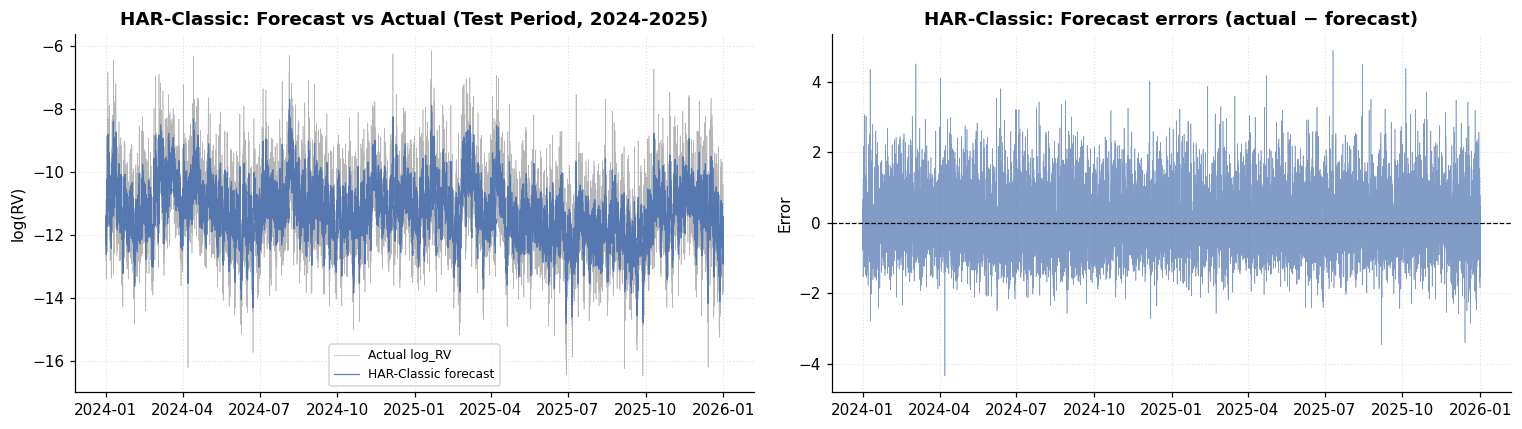

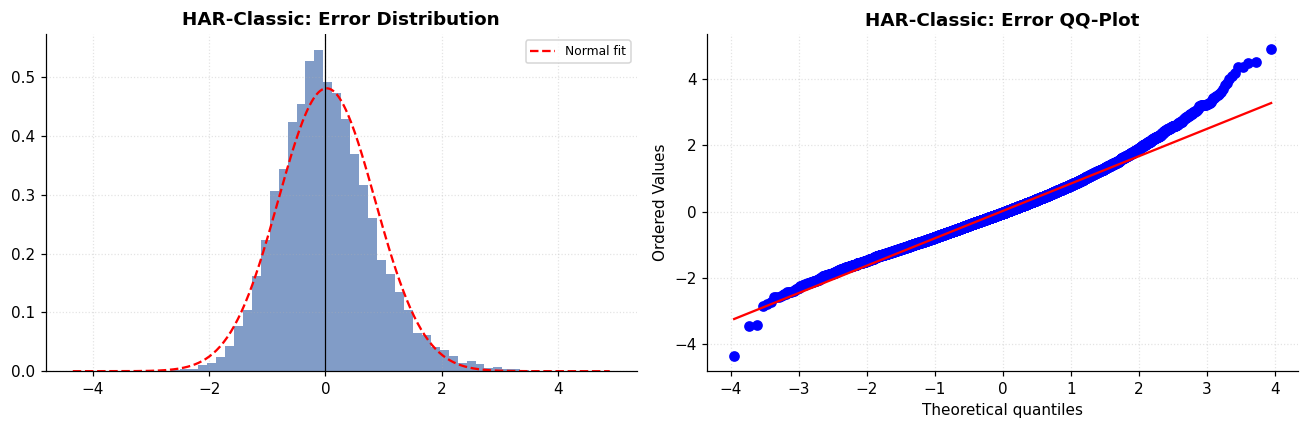

                     period     N    RMSE     MAE    Bias   QLIKE
fold                                                             
1     2022-01-01→2022-05-26  3502  0.8670  0.6718 -0.0056  0.6101
2     2022-05-27→2022-10-19  3502  0.8597  0.6635 -0.0057  0.6248
3     2022-10-20→2023-03-14  3504  1.0291  0.7966 -0.1452  0.8952
4     2023-03-15→2023-08-07  3502  0.9768  0.7551 -0.1068  0.7671
5     2023-08-08→2023-12-31  3504  0.9193  0.7021 -0.0693  0.8646


In [147]:
plot_forecast_vs_actual(test_index, y_test_log, PRED["test"]["HAR-Classic"], "HAR-Classic", MC["HAR-Classic"])
plot_error_dist(y_test_log - PRED["test"]["HAR-Classic"], "HAR-Classic", MC["HAR-Classic"])
print(fold_table("HAR-Classic").round(4).to_string())

#### 7.2 — HAR-Extended

In [148]:
res_extended = run_har("HAR-Extended", HAR_EXTENDED_FEATS)

print("  HAR-Extended — final fit on train+validation (HAC standard errors, 24 lags):")
print(res_extended.summary().tables[1])
print(f"  In-sample R² (estimation window, n={int(res_extended.nobs):,}): {res_extended.rsquared:.4f}")
report("HAR-Extended")

# Nested-model comparison with HAC-robust Wald test of the two additional coefficients
wald = res_extended.wald_test("jump_24h = 0, RS_minus_24h = 0", scalar=True)
print(f"\n  HAC Wald test, H0: jump_24h = RS_minus_24h = 0  ->  chi2 = {float(wald.statistic):.3f}, p = {float(wald.pvalue):.4g}")

  HAR-Extended — final fit on train+validation (HAC standard errors, 24 lags):
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.1690      0.054     -3.111      0.002      -0.276      -0.063
log_RV_1h        0.4333      0.006     74.795      0.000       0.422       0.445
log_RV_24h       0.3805      0.010     37.969      0.000       0.361       0.400
log_RV_168h      0.1880      0.009     20.659      0.000       0.170       0.206
jump_24h        -0.6352      0.055    -11.455      0.000      -0.744      -0.527
RS_minus_24h    -0.0029      0.049     -0.059      0.953      -0.099       0.093
  In-sample R² (estimation window, n=61,892): 0.6448
  HAR-Extended     VALIDATION (pooled WFV)  RMSE=0.9339  MAE=0.7195  Bias=-0.0739  R2=0.5926  QLIKE=0.7556  (n=17,514)
  HAR-Extended     TEST (held-out)          RMSE=0.8305  MAE=0.6449  Bias=-0.0042  R2=0.5352  QLIKE=0

HAR-Extended adds the jump ratio and the downside-semivariance ratio. Two separate questions are answered separately: whether the two extra coefficients are jointly different from zero **in sample** (HAC Wald test above), and whether the extended model forecasts more accurately **out of sample** (validation/test metrics above and the DM test in Section 10). In-sample significance does not imply out-of-sample improvement. Because HAR-Classic is nested within HAR-Extended, the standard DM comparison is interpreted cautiously; a dedicated nested-model test such as Clark–West is left as a robustness extension.

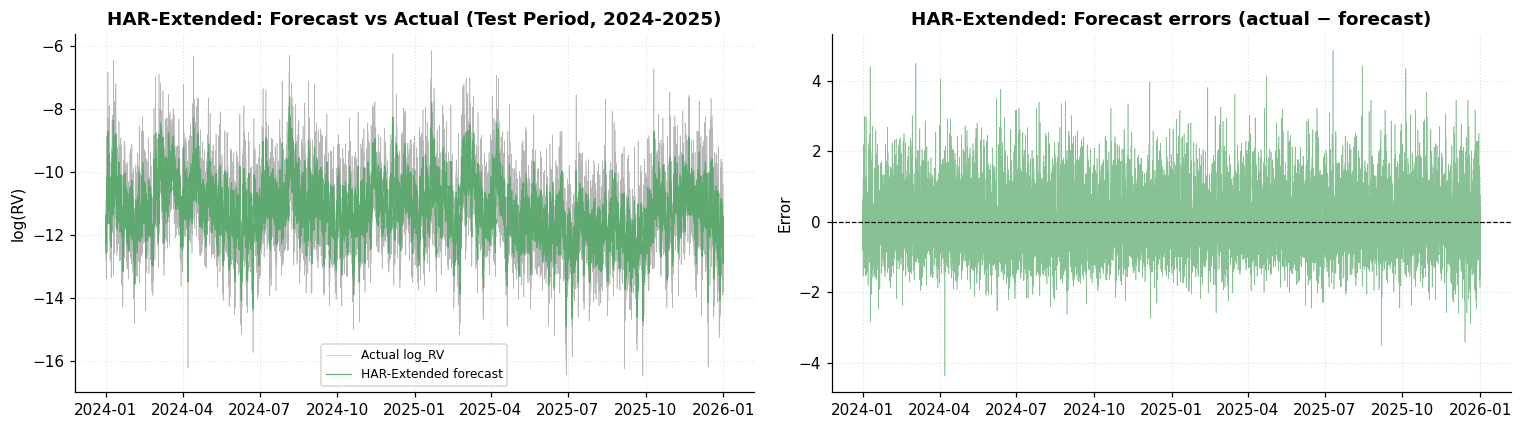

                     period     N    RMSE     MAE    Bias   QLIKE
fold                                                             
1     2022-01-01→2022-05-26  3502  0.8691  0.6746 -0.0124  0.6094
2     2022-05-27→2022-10-19  3502  0.8613  0.6655 -0.0143  0.6185
3     2022-10-20→2023-03-14  3504  1.0267  0.7938 -0.1375  0.9119
4     2023-03-15→2023-08-07  3502  0.9790  0.7573 -0.1113  0.7673
5     2023-08-08→2023-12-31  3504  0.9223  0.7061 -0.0940  0.8706


In [149]:
plot_forecast_vs_actual(test_index, y_test_log, PRED["test"]["HAR-Extended"], "HAR-Extended", MC["HAR-Extended"])
print(fold_table("HAR-Extended").round(4).to_string())

## 8 — MC-GARCH

**Model.** An adaptation of the Multiplicative Component GARCH of Engle & Sokalska (2012) to hourly log realized variance, estimated in R (`mcgarch_btc_final.R`, `rugarch`):

$$RV_t = h_t \cdot s_{hod(t)} \cdot z_t$$

- $h_t$: the previous complete UTC day's mean hourly RV (known at the start of day $t$),
- $s_{hod}$: a geometric hour-of-day factor, estimated so that the mean of the remaining log stochastic component $\log z$ is zero within each UTC hour of the estimation sample, which makes the zero-mean specification (`include.mean = FALSE`) consistent,
- $\log z_t$: AR(1)–GARCH(1,1).

**Point forecast:** $\widehat{\log RV}_t=\log h_t+\log s_{hod}+\varphi\,\log z_{t-1}$. The conditional variance $\sigma_t^2$ of the GARCH block does **not** enter this point forecast; it would matter for density or interval forecasts. A homoskedastic AR(1) variant (Gaussian ML, `MC-AR(1)`) is reported as a diagnostic of what the GARCH block adds to the point forecast.

**Out-of-sample protocol.** Parameters are estimated once on the estimation sample and held fixed; the filter is then run continuously through the evaluation period, so every forecast uses only information available before the hour. There is **no** mean-filling: every evaluation hour has a genuine out-of-sample forecast. Leakage tests (truncation and perturbation) were run in R. The Python side only reads the CSVs.

In [150]:
# 8.1 Load the R outputs

def read_r(fn):
    d = pd.read_csv(os.path.join(MCGARCH_DIR, fn))
    d["datetime_utc"] = pd.to_datetime(d["datetime_utc"], utc=True)
    return d

mc_f = read_r("mcgarch_forecasts.csv").set_index("datetime_utc").sort_index()
mc_w = read_r("mcgarch_wfv_forecasts.csv").set_index("datetime_utc").sort_index()
assert mc_f.index.is_unique and mc_w.index.is_unique, "Duplicate timestamps in the R forecast files"

# Test: forecasts for every evaluation hour, no filling
mc_test = mc_f.reindex(test_index)
assert mc_test[["log_RV_hat", "log_RV_hat_ar1"]].notna().all().all(), "Missing MC-GARCH test forecast"
# Validation: genuine fold-wise forecasts for every evaluation hour
mc_val = mc_w.reindex(val_index)
assert mc_val[["log_RV_hat", "log_RV_hat_ar1"]].notna().all().all(), "Missing MC-GARCH WFV forecast"
assert np.array_equal(mc_val["fold"].astype(int).values, val_fold), "Fold assignment differs from R"

register("MC-GARCH", mc_val["log_RV_hat"].values, mc_test["log_RV_hat"].values)
register("MC-AR(1)", mc_val["log_RV_hat_ar1"].values, mc_test["log_RV_hat_ar1"].values)

print(f"  Test forecasts       : {len(mc_test):,} of {len(test_index):,} evaluation hours (none filled)")
print(f"  Validation forecasts : {len(mc_val):,} of {len(val_index):,} evaluation hours (none filled)")

  Test forecasts       : 17,539 of 17,539 evaluation hours (none filled)
  Validation forecasts : 17,514 of 17,514 evaluation hours (none filled)


In [151]:
# 8.2 Cross-check of the Python metrics with the R walk-forward table (same hours, same definitions)

r_wfv = pd.read_csv(os.path.join(MCGARCH_DIR, "mcgarch_wfv.csv"))
chk = []
for f, (_, row) in zip(FOLDS, r_wfv.iterrows()):
    msk = val_fold == f["fold"]
    m = metrics(y_val_log[msk], PRED["val"]["MC-GARCH"][msk])
    m1 = metrics(y_val_log[msk], PRED["val"]["MC-AR(1)"][msk])
    chk.append({"fold": f["fold"],
                "d_RMSE": m["RMSE"] - row["rmse"], "d_MAE": m["MAE"] - row["mae"], "d_Bias": m["Bias"] - row["bias"],
                "d_QLIKE": m["QLIKE"] - row["qlike"], "d_RMSE_ar1": m1["RMSE"] - row["rmse_ar1"],
                "d_QLIKE_ar1": m1["QLIKE"] - row["qlike_ar1"]})
chk = pd.DataFrame(chk).set_index("fold")
print("  Python − R differences per fold (should be ~0):")
print(chk.to_string(float_format=lambda x: f"{x:.2e}"))
assert chk[["d_RMSE", "d_MAE", "d_Bias", "d_RMSE_ar1"]].abs().max().max() < 1e-6, "Python and R metrics disagree"
if chk[["d_QLIKE", "d_QLIKE_ar1"]].abs().max().max() >= 1e-6:
    print("  WARNING: QLIKE differs between Python and R (check that the QLIKE floor definition is identical).")

  Python − R differences per fold (should be ~0):
        d_RMSE     d_MAE   d_Bias   d_QLIKE  d_RMSE_ar1  d_QLIKE_ar1
fold                                                                
1     3.33e-16  1.11e-16 3.19e-16 -1.55e-15    5.55e-16    -9.99e-16
2    -5.55e-16 -2.22e-16 1.07e-15  5.55e-16    3.33e-16     5.55e-16
3     2.66e-15 -2.22e-16 1.22e-15  6.00e-15   -2.22e-16     5.33e-15
4     4.44e-16  6.66e-16 1.04e-15  2.44e-15    3.33e-16     0.00e+00
5     2.22e-16  1.11e-16 1.94e-16  1.15e-14    3.33e-16     9.99e-15


  Walk-forward parameter table from R:
 fold            from_utc              to_utc  train_hrs  n_forecast  n_eval      phi  phi_ar1  persistence  convergence solver
    1 2022-01-01 00:00:00 2022-05-26 23:00:00      44553        3504    3502 0.504714 0.516798     0.989800            0 hybrid
    2 2022-05-27 00:00:00 2022-10-19 23:00:00      48057        3504    3502 0.506542 0.517502     0.990136            0 hybrid
    3 2022-10-20 00:00:00 2023-03-14 23:00:00      51561        3504    3504 0.504390 0.516431     0.987997            0 hybrid
    4 2023-03-15 00:00:00 2023-08-07 23:00:00      55065        3504    3502 0.514338 0.524870     0.991915            0 hybrid
    5 2023-08-08 00:00:00 2023-12-31 23:00:00      58569        3504    3504 0.519100 0.528851     0.992797            0 hybrid

  Final-model metadata (R):
phi                                 0.529425
phi_ar1                             0.538943
omega                               0.005813
alpha                        

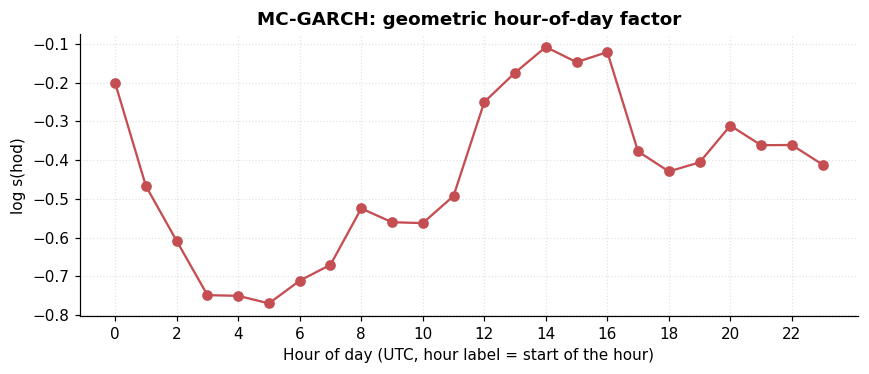

In [152]:
# 8.3 Estimated parameters and R-side diagnostics

print("  Walk-forward parameter table from R:")
print(r_wfv[["fold", "from_utc", "to_utc", "train_hrs", "n_forecast", "n_eval", "phi", "phi_ar1",
             "persistence", "convergence", "solver"]].to_string(index=False))

try:
    meta = pd.read_csv(os.path.join(MCGARCH_DIR, "mcgarch_metadata.csv"))
    print("\n  Final-model metadata (R):")
    print(meta.T.to_string(header=False) if len(meta) == 1 else meta.to_string(index=False))
except Exception as e:
    print("  (metadata file not readable:", e, ")")

diur = pd.read_csv(os.path.join(MCGARCH_DIR, "mcgarch_diurnal.csv"))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(diur["hod"], np.log(diur["s_i"]), marker="o", color=MC["MC-GARCH"])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("Hour of day (UTC, hour label = start of the hour)")
ax.set_ylabel("log s(hod)"); ax.set_title("MC-GARCH: geometric hour-of-day factor", fontweight="bold")
plt.tight_layout(); plt.show()

The diurnal factor is the estimated intraday seasonality in log scale; it is estimated so that the mean of the remaining log stochastic component is zero within each UTC hour in the estimation sample. The persistence value in the table is $\alpha+\beta$ of the GARCH block; values close to 1 indicate a highly persistent conditional variance. The metadata printed above includes the Ljung–Box and ARCH-LM diagnostics of the standardised residuals computed in R; these are descriptive diagnostics of the fitted AR(1) mean equation and are not repeated here.

  MC-GARCH         VALIDATION (pooled WFV)  RMSE=0.9542  MAE=0.7299  Bias=-0.0448  R2=0.5746  QLIKE=0.8446  (n=17,514)
  MC-GARCH         TEST (held-out)          RMSE=0.8541  MAE=0.6608  Bias=+0.0198  R2=0.5084  QLIKE=0.5597  (n=17,539)
  MC-AR(1)         VALIDATION (pooled WFV)  RMSE=0.9531  MAE=0.7290  Bias=-0.0438  R2=0.5756  QLIKE=0.8434  (n=17,514)
  MC-AR(1)         TEST (held-out)          RMSE=0.8522  MAE=0.6591  Bias=+0.0194  R2=0.5107  QLIKE=0.5575  (n=17,539)


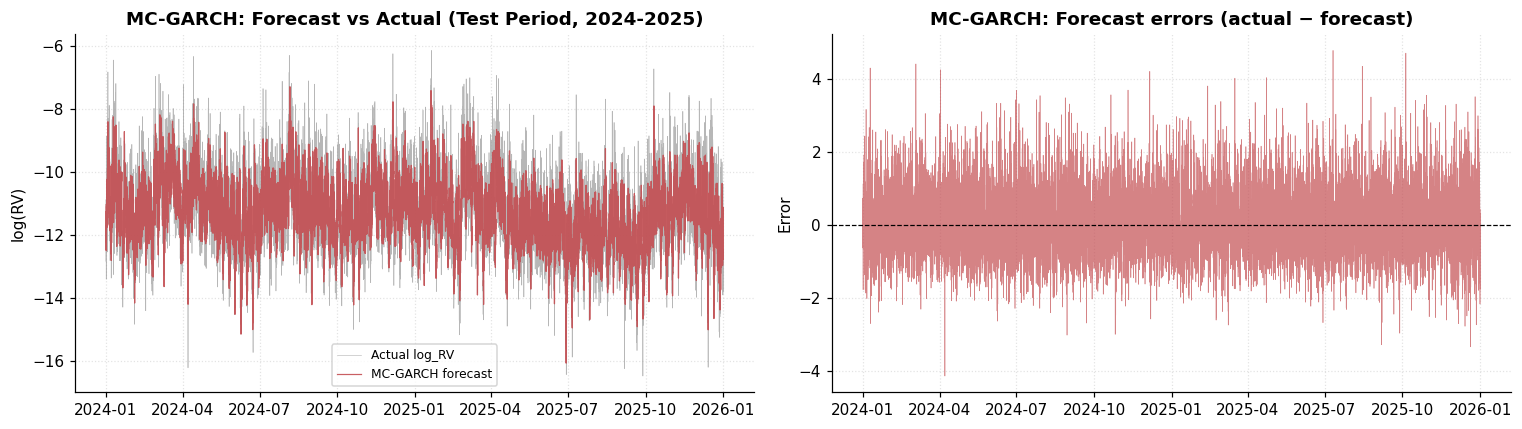


  MC-GARCH per-fold validation metrics:
                     period     N    RMSE     MAE    Bias   QLIKE
fold                                                             
1     2022-01-01→2022-05-26  3502  0.8800  0.6746 -0.0090  0.6390
2     2022-05-27→2022-10-19  3502  0.8840  0.6802 -0.0043  0.6753
3     2022-10-20→2023-03-14  3504  1.0459  0.8058 -0.0948  1.0147
4     2023-03-15→2023-08-07  3502  0.9998  0.7688 -0.0758  0.8527
5     2023-08-08→2023-12-31  3504  0.9505  0.7200 -0.0399  1.0409


In [153]:
# 8.4 Metrics, forecast plot

report("MC-GARCH")
report("MC-AR(1)")
plot_forecast_vs_actual(test_index, y_test_log, PRED["test"]["MC-GARCH"], "MC-GARCH", MC["MC-GARCH"])
print("\n  MC-GARCH per-fold validation metrics:")
print(fold_table("MC-GARCH").round(4).to_string())

Because every number above is produced on exactly the same evaluation hours as the other models, the comparison with HAR and LSTM involves no alignment step and no filled forecasts.

Two remarks on the specification. First, the point forecast uses only the AR(1) mean equation; if the homoskedastic `MC-AR(1)` variant forecasts as well as or better than `MC-GARCH`, the GARCH variance block adds nothing to *point* forecasts of log RV (its value would lie in density forecasts, which are not evaluated here). Second, the Ljung–Box and ACF diagnostics of the standardised residuals printed in 8.3 should be read as a check of the AR(1) mean equation: any remaining low-order autocorrelation there means that AR(1) is a parsimonious rather than a complete description of the dynamics. `MC-GARCH` and `MC-AR(1)` are compared by a dedicated DM test in Section 10, which is kept outside the multiple-testing family of the six main models.

## 9 — LSTM

A two-layer LSTM (64 → 32 hidden units, dropout 0.2) over the 9-feature set of Section 0 with a 168-hour (one-week) lookback window.

**Sequence construction.** For a target hour at position $p$ on the continuous hourly axis, the input window is rows $p-167,\ldots,p$ (168 rows, including row $p$ itself, whose features are built from hours $<p$ only). Validation and test windows reach back into the preceding period for their first 167 rows: those rows are **input context only** — they are never targets and they contain no information about the target hour — so no validation or test hour is lost to sequence construction, and no leakage arises.

**Training protocol.** The `RobustScaler` is fitted once on the initial 2016–2021 training rows and held fixed for all walk-forward folds and for the final model (it is not re-estimated per fold; this is leakage-free and keeps the input transformation identical everywhere). Walk-forward validation trains a fresh network on each expanding window; the early-stopping hold-out is the last 10 % of the *training* sequences (chronologically), never the validation fold. The final model is trained on train + validation (hold-out again taken from the end of that sample), three seeds are averaged, and the held-out test set is used exclusively for the final forecasts.

In [154]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, Callback
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [155]:
# 9.1 Scaling and sequence tensors

# RobustScaler is fit on training rows ONLY and then applied to every row (no validation/test statistics enter the scaler).
scaler = RobustScaler().fit(df.loc[df["feat_ok"] & is_train, LSTM_FEATS])

N = len(df)
n_feat = len(LSTM_FEATS)
FV = np.full((N, n_feat), np.nan, np.float32)
FV[df["feat_ok"].values] = scaler.transform(df.loc[df["feat_ok"], LSTM_FEATS]).astype(np.float32)
Y = df["log_RV"].to_numpy(np.float32)

FIRST_SEQ_POS = int(np.argmax(df["feat_ok"].values)) + LOOKBACK - 1     # first position with a full, finite window
WIN = sliding_window_view(FV, LOOKBACK, axis=0)                         # (N-LB+1, n_feat, LB); WIN[j][:, k] = FV[j+k]

def make_seqs(positions):
    """Sequences ending at the given positions: window = FV[p-LB+1 : p+1]."""
    positions = np.asarray(positions)
    assert positions.min() >= FIRST_SEQ_POS, "Window would contain warm-up rows"
    X = np.ascontiguousarray(WIN[positions - LOOKBACK + 1].transpose(0, 2, 1))
    assert np.isfinite(X).all(), "Non-finite values in an LSTM window"
    return X, Y[positions]

# Target positions: usable hours with a complete window
pos_use = np.flatnonzero(df["use"].values & (np.arange(N) >= FIRST_SEQ_POS))
pos_val = pos_of(val_index)
pos_test = pos_of(test_index)
assert len(pos_test) == EXPECTED_TEST_EVAL and len(pos_val) == len(val_index)
assert pos_val.min() >= FIRST_SEQ_POS, "A validation hour lacks a full window"

# Alignment self-test: window of a random target equals the 168 feature rows ending at that target
_rng = np.random.default_rng(RANDOM_SEED)
_chk = _rng.choice(pos_test, 20, replace=False)
_X, _y = make_seqs(_chk)
for _i, _p in enumerate(_chk):
    assert np.array_equal(_X[_i], FV[_p - LOOKBACK + 1:_p + 1]) and _y[_i] == Y[_p]
    assert df.index[_p - LOOKBACK + 1] == df.index[_p] - pd.Timedelta(hours=LOOKBACK - 1)

print(f"  Input shape            : ({LOOKBACK}, {n_feat})")
print(f"  First possible target  : {df.index[FIRST_SEQ_POS]}  (position {FIRST_SEQ_POS})")
print(f"  Validation targets     : {len(pos_val):,}   (all evaluation hours kept)")
print(f"  Test targets           : {len(pos_test):,}   (all evaluation hours kept)")
print(f"  First test window      : {df.index[pos_test[0] - LOOKBACK + 1]} → {df.index[pos_test[0]]}  "
      f"(first {LOOKBACK-1} rows are input context only)")

  Input shape            : (168, 9)
  First possible target  : 2016-12-15 14:00:00+00:00  (position 335)
  Validation targets     : 17,514   (all evaluation hours kept)
  Test targets           : 17,539   (all evaluation hours kept)
  First test window      : 2023-12-25 01:00:00+00:00 → 2024-01-01 00:00:00+00:00  (first 167 rows are input context only)


Every evaluation hour of the validation and test periods has a forecast: the first test target (2024-01-01 00:00 or the first usable hour after it) is predicted from a window whose earlier rows lie in December 2023. These earlier rows are inputs only.

In [156]:
# 9.2 Architecture and training helpers

class EpochLogger(Callback):
    """Prints every 10th epoch (loss, hold-out loss, learning rate)."""
    def __init__(self, prefix=""): super().__init__(); self.prefix = prefix
    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % 10 == 0 or epoch == 0:
            logs = logs or {}
            lr = float(tf.keras.backend.get_value(self.model.optimizer.learning_rate))
            print(f"    {self.prefix}ep {epoch+1:3d}  loss={logs.get('loss',0):.5f}  holdout={logs.get('val_loss',0):.5f}  lr={lr:.2e}", flush=True)

def build_lstm():
    """Two-layer LSTM (64 -> 32) with dropout, mapping to a single log-RV forecast."""
    model = keras.Sequential([
        keras.Input(shape=(LOOKBACK, n_feat)),
        layers.LSTM(LSTM_PARAMS["hidden_size"], return_sequences=True),
        layers.Dropout(LSTM_PARAMS["dropout"]),
        layers.LSTM(LSTM_PARAMS["hidden_size"] // 2, return_sequences=False),
        layers.Dropout(LSTM_PARAMS["dropout"]),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(LSTM_PARAMS["learning_rate"]), loss="mse")
    return model

def fit_lstm(train_pos, seed, epochs, patience, reduce_lr=False, tag=""):
    """Train on the first 90 % of train_pos (chronological); the last 10 % is the early-stopping hold-out."""
    train_pos = np.sort(train_pos)
    n_hold = int(len(train_pos) * 0.10)
    fit_pos, hold_pos = train_pos[:-n_hold], train_pos[-n_hold:]
    assert fit_pos.max() < hold_pos.min()
    Xf, yf = make_seqs(fit_pos); Xh, yh = make_seqs(hold_pos)
    tf.keras.utils.set_random_seed(seed)
    m = build_lstm()
    cbs = [EarlyStopping("val_loss", patience=patience, restore_best_weights=True, verbose=0), EpochLogger(tag)]
    if reduce_lr:
        cbs.append(ReduceLROnPlateau("val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=0))
    h = m.fit(Xf, yf, validation_data=(Xh, yh), epochs=epochs, batch_size=LSTM_PARAMS["batch_size"],
              callbacks=cbs, shuffle=False, verbose=0).history
    info = {"epochs_run": len(h["loss"]), "best_epoch": int(np.argmin(h["val_loss"])) + 1,
            "best_holdout_loss": float(np.min(h["val_loss"])), "n_fit": len(fit_pos), "n_holdout": len(hold_pos)}
    return m, h, info

def predict_pos(model, positions):
    X, _ = make_seqs(positions)
    return model.predict(X, batch_size=1024, verbose=0).flatten()

In [157]:
# 9.3 Obtain the LSTM forecasts: train (RETRAIN_LSTM = True) or load the saved canonical forecasts (False)

def _find_cache(fn):
    for d in [OUT_DIR, DATA_DIR]:
        p = os.path.join(d, fn)
        if os.path.exists(p): return p
    raise FileNotFoundError(f"{fn} not found in {OUT_DIR} or {DATA_DIR}; run once with RETRAIN_LSTM = True")

all_fold_histories, fold_infos, final_infos, final_hist0 = [], [], [], None
pos_val_by_fold = [pos_of(f["eval_idx"]) for f in FOLDS]

if RETRAIN_LSTM:
    # ---- Walk-forward validation: fresh model per fold on the expanding window ----
    lstm_val_parts = []
    for k, f in enumerate(FOLDS):
        tr_pos = pos_use[pos_use < df.index.get_loc(f["start"])]
        print(f"\n  ── WFV fold {k+1}/{len(FOLDS)} | training targets: {len(tr_pos):,} | evaluation hours: {len(f['eval_idx']):,}")
        m, h, info = fit_lstm(tr_pos, RANDOM_SEED + k, LSTM_WFV_PARAMS["epochs"], LSTM_WFV_PARAMS["patience"], tag=f"fold {k+1} | ")
        lstm_val_parts.append(predict_pos(m, pos_val_by_fold[k]))
        info.update({"fold": k + 1}); fold_infos.append(info)
        all_fold_histories.append({"fold": k + 1, "period": f"{f['start'].date()}→{f['end'].date()}", "train": h["loss"], "val": h["val_loss"]})
        print(f"     epochs run={info['epochs_run']}  best epoch={info['best_epoch']}  best hold-out MSE={info['best_holdout_loss']:.5f}")
        del m; tf.keras.backend.clear_session()
    lstm_val = np.concatenate(lstm_val_parts)

    # ---- Final models: train + validation, 3 seeds, test forecasts averaged ----
    tv_pos = pos_use[pos_use <= df.index.get_loc(df.index[is_val][-1])]
    print(f"\n  Final training targets (train+validation): {len(tv_pos):,}")
    runs = []
    for r in range(LSTM_FINAL_PARAMS["n_runs"]):
        seed = RANDOM_SEED + r
        print(f"\n  ── Final run {r+1}/{LSTM_FINAL_PARAMS['n_runs']} (seed={seed}) ──")
        m, h, info = fit_lstm(tv_pos, seed, LSTM_FINAL_PARAMS["epochs"], LSTM_FINAL_PARAMS["patience"], reduce_lr=True, tag=f"run {r+1} | ")
        print(f"     epochs run={info['epochs_run']}  best epoch={info['best_epoch']}  best hold-out MSE={info['best_holdout_loss']:.5f}")
        info.update({"run": r + 1, "seed": seed}); final_infos.append(info)
        runs.append(predict_pos(m, pos_test))
        if r == 0: final_hist0 = h; m.summary()
        m.save(os.path.join(OUT_DIR, f"lstm_final_run{r+1}.keras"))
        del m; tf.keras.backend.clear_session()
    lstm_test = np.mean(runs, axis=0)

    pd.DataFrame({"datetime_utc": test_index, "y_true_log": y_test_log, "lstm_pred_log": lstm_test}).to_csv(
        os.path.join(OUT_DIR, "lstm_test_predictions.csv"), index=False)
    pd.DataFrame({"datetime_utc": val_index, "fold": val_fold, "y_true_log": y_val_log, "lstm_pred_log": lstm_val}).to_csv(
        os.path.join(OUT_DIR, "lstm_wfv_predictions.csv"), index=False)
    print(f"\n  Saved lstm_test_predictions.csv and lstm_wfv_predictions.csv to {OUT_DIR}")
else:
    c_test = pd.read_csv(_find_cache("lstm_test_predictions.csv")); c_test["datetime_utc"] = pd.to_datetime(c_test["datetime_utc"], utc=True)
    c_val = pd.read_csv(_find_cache("lstm_wfv_predictions.csv")); c_val["datetime_utc"] = pd.to_datetime(c_val["datetime_utc"], utc=True)
    assert pd.DatetimeIndex(c_test["datetime_utc"]).equals(test_index), "Cached LSTM test forecasts do not match the test index"
    assert pd.DatetimeIndex(c_val["datetime_utc"]).equals(val_index), "Cached LSTM WFV forecasts do not match the validation index"
    assert np.allclose(c_test["y_true_log"].values, y_test_log) and np.allclose(c_val["y_true_log"].values, y_val_log)
    assert np.array_equal(c_val["fold"].astype(int).values, val_fold), "Cached LSTM fold assignments differ"
    lstm_test, lstm_val = c_test["lstm_pred_log"].values, c_val["lstm_pred_log"].values
    print("  Loaded cached LSTM forecasts (RETRAIN_LSTM = False)")

register("LSTM", lstm_val, lstm_test)

  Loaded cached LSTM forecasts (RETRAIN_LSTM = False)


Early stopping never looks at the validation fold or the test set: its hold-out is a block at the end of the *training* sequences. The stopping epochs and best hold-out losses printed above document how long each network trained. Because GPU training is not bit-wise reproducible, the canonical forecasts are written to CSV on the first run and can be re-loaded with `RETRAIN_LSTM = False`; all tables, tests and figures downstream are recomputed from those CSVs.

In [158]:
# 9.4 Training diagnostics (available when the networks were trained in this session)

if all_fold_histories:
    fold_colours = ["#4C72B0", "#55A868", "#C44E52", "#DD8452", "#9B59B6"]
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for h in all_fold_histories:
        c = fold_colours[h["fold"] - 1]
        axes[0].plot(h["train"], color=c, lw=1.2, label=f"Fold {h['fold']} fit")
        axes[0].plot(h["val"], color=c, lw=1.2, ls="--", alpha=0.7)
    axes[0].set_title("WFV: training (solid) vs early-stopping hold-out (dashed) MSE", fontweight="bold")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE (log_RV)"); axes[0].legend(fontsize=7, ncol=2)
    axes[1].plot(final_hist0["loss"], label="Fit loss", color="#4C72B0")
    axes[1].plot(final_hist0["val_loss"], label="Hold-out loss", color="#DD8452")
    axes[1].set_title("Final model (seed 42): fit vs hold-out MSE", fontweight="bold")
    axes[1].set_xlabel("Epoch"); axes[1].legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figure_lstm_training.png", dpi=200); plt.show()
    print(pd.DataFrame(fold_infos).set_index("fold").to_string())
    print(pd.DataFrame(final_infos).set_index("run").to_string())
else:
    print("  (cached forecasts loaded: no training histories in this session)")

  (cached forecasts loaded: no training histories in this session)


  LSTM             VALIDATION (pooled WFV)  RMSE=0.9426  MAE=0.7258  Bias=-0.1271  R2=0.5850  QLIKE=0.7107  (n=17,514)
  LSTM             TEST (held-out)          RMSE=0.7841  MAE=0.6043  Bias=+0.0095  R2=0.5857  QLIKE=0.4654  (n=17,539)

  LSTM per-fold validation metrics:
                     period     N    RMSE     MAE    Bias   QLIKE
fold                                                             
1     2022-01-01→2022-05-26  3502  0.8534  0.6719 -0.1087  0.5272
2     2022-05-27→2022-10-19  3502  0.8449  0.6601 -0.0672  0.5740
3     2022-10-20→2023-03-14  3504  1.0862  0.8425 -0.2588  0.8321
4     2023-03-15→2023-08-07  3502  0.9818  0.7570 -0.1378  0.7455
5     2023-08-08→2023-12-31  3504  0.9253  0.6973 -0.0627  0.8746


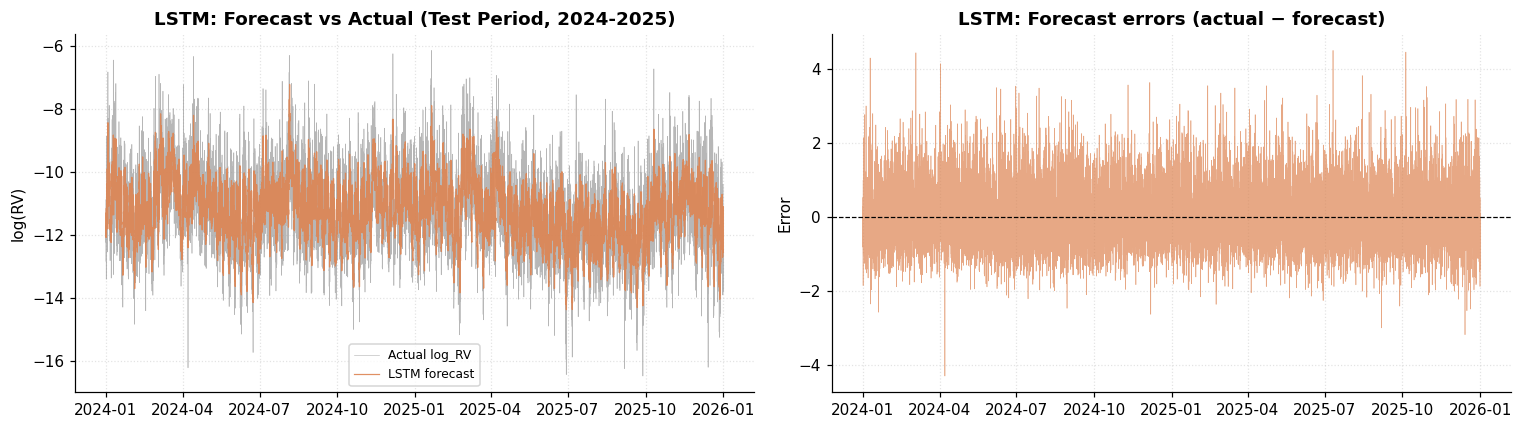

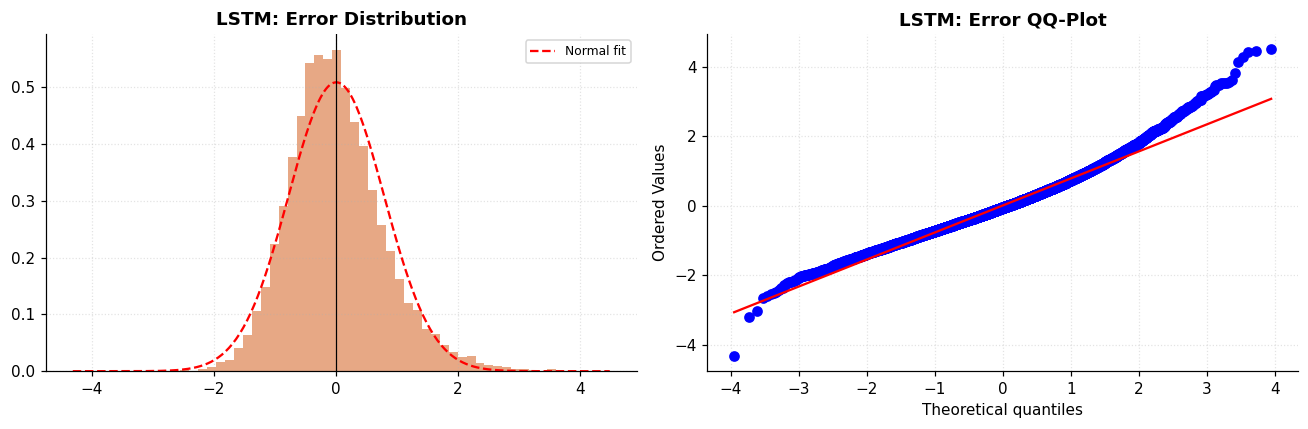

In [159]:
# 9.5 Metrics and plots

report("LSTM")
print("\n  LSTM per-fold validation metrics:")
print(fold_table("LSTM").round(4).to_string())
plot_forecast_vs_actual(test_index, y_test_log, PRED["test"]["LSTM"], "LSTM", MC["LSTM"])
plot_error_dist(y_test_log - PRED["test"]["LSTM"], "LSTM", MC["LSTM"])

The LSTM is evaluated with the same metric function, on the same hours and with the same walk-forward / held-out distinction as every other model. Fold-to-fold differences may reflect changes in volatility conditions as well as estimation variability; the period-level volatility summaries in Section 10 give context but do not establish causality. Whether the LSTM is more or less accurate than HAR or MC-GARCH is a statistical question answered by the DM tests, not by the ranking of point estimates.

In [160]:
# 9.6 SHAP feature importance (final networks saved in 9.3). Skipped if the models are not available.

try:
    import shap
    paths = [os.path.join(OUT_DIR, f"lstm_final_run{r+1}.keras") for r in range(LSTM_FINAL_PARAMS["n_runs"])]
    if not all(os.path.exists(p) for p in paths):
        raise FileNotFoundError("final model files not found (train with RETRAIN_LSTM = True first)")
    rng = np.random.default_rng(RANDOM_SEED)
    bg_pos = rng.choice(pos_use[pos_use <= df.index.get_loc(df.index[is_val][-1])], 500, replace=False)
    ex_pos = rng.choice(pos_test, 200, replace=False)
    X_bg, _ = make_seqs(bg_pos); X_ex, _ = make_seqs(ex_pos)

    shap_all = []
    for r, p in enumerate(paths):
        mdl = keras.models.load_model(p)
        sv = shap.GradientExplainer(mdl, X_bg).shap_values(X_ex)
        sv = np.asarray(sv[0] if isinstance(sv, list) else sv)
        if sv.ndim == 4 and sv.shape[-1] == 1: sv = sv[..., 0]
        assert sv.shape == X_ex.shape, f"Unexpected SHAP shape {sv.shape}; expected {X_ex.shape}"
        shap_all.append(np.abs(sv).mean(axis=(0, 1)))
        print(f"  SHAP run {r+1} done. Top feature: {LSTM_FEATS[int(np.argmax(shap_all[-1]))]}")
        del mdl; tf.keras.backend.clear_session()

    shap_df = pd.DataFrame({"Feature": LSTM_FEATS, "Mean|SHAP|": np.mean(shap_all, axis=0),
                            "Std|SHAP|": np.std(shap_all, axis=0)}).sort_values("Mean|SHAP|", ascending=False)
    print(shap_df.to_string(index=False, float_format=lambda x: f"{x:.5f}"))
    shap_df.to_csv(f"{OUT_DIR}/table_shap.csv", index=False)

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(shap_df["Feature"], shap_df["Mean|SHAP|"], xerr=shap_df["Std|SHAP|"], color=MC["LSTM"], alpha=0.85,
            edgecolor="white", error_kw={"elinewidth": 1.2, "capsize": 3, "ecolor": "gray"})
    ax.set_xlabel("Mean |SHAP value| (3-seed average ± std)"); ax.invert_yaxis()
    ax.set_title("LSTM: SHAP feature importance (final networks, GradientExplainer)", fontweight="bold")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figure_shap.png", dpi=200); plt.show()
except Exception as e:
    print("  SHAP was not computed in this run (" + type(e).__name__ + "). It requires the saved final networks, i.e. a run with RETRAIN_LSTM = True;")
    print("  forecast metrics and DM tests are unaffected. The SHAP table of the canonical run is in table_shap.csv.")

  SHAP was not computed in this run (FileNotFoundError). It requires the saved final networks, i.e. a run with RETRAIN_LSTM = True;
  forecast metrics and DM tests are unaffected. The SHAP table of the canonical run is in table_shap.csv.


SHAP is computed only in the canonical training run (`RETRAIN_LSTM = True`); in a cached run the cell above prints a notice instead of a table. Mean absolute SHAP values are averaged over the 168 time steps, 200 test sequences and the three final networks, which are the same networks that produced the test forecasts. The ranking shows which inputs the network relies on; it is a description of the fitted function, not a causal statement.

## 10 — MODEL COMPARISON & DIEBOLD–MARIANO TESTS

**Sample.** The comparison uses the shared evaluation hours of Section 4 — identical for every model, no alignment or trimming. Results are shown separately for the **validation period** (five walk-forward folds pooled; supporting evidence) and the **held-out test period** (primary evidence). Validation-period DM results pool genuine non-overlapping walk-forward forecasts but combine five re-estimated forecast origins, so they are treated as supporting evidence only. The 15 pairwise comparisons per loss, including the central hypotheses on HAR vs LSTM and HAR-Classic vs HAR-Extended, form one Holm family.

**Test.** For two models with loss series $L^{(1)}_t, L^{(2)}_t$ the differential is $d_t=L^{(1)}_t-L^{(2)}_t$ and $H_0:E[d_t]=0$. The statistic is $\bar d/\sqrt{\hat\Omega/n}$ with a **Bartlett-kernel (Newey–West) HAC** long-run variance $\hat\Omega$. Horizon is one hour ahead, but hourly volatility losses are strongly serially correlated, so the main bandwidth is **24 lags** (one day); 12 and 168 lags are reported as a sensitivity analysis. p-values come from the standard normal. **A positive statistic means model 1 has the higher loss (model 2 is more accurate).** Two losses are used, each tested separately: the squared error on the log scale and QLIKE on the RV scale. The same procedure is applied to every pair. Within each loss, the 15 pairwise p-values among the six main models are adjusted with the **Holm** step-down procedure; a conclusion is drawn only from the Holm-adjusted p-value.

In [161]:
# 10.1 DM machinery

def nw_lrv(d, lag):
    """Bartlett-kernel (Newey-West) long-run variance of a series."""
    d = np.asarray(d, float); n = len(d)
    assert np.isfinite(d).all() and 0 <= lag < n, "Invalid loss differential or lag"
    d = d - d.mean()
    lrv = float(d @ d) / n
    for k in range(1, lag + 1):
        lrv += 2.0 * (1.0 - k / (lag + 1.0)) * float(d[k:] @ d[:-k]) / n
    return lrv

def dm_hac(l1, l2, lag):
    d = np.asarray(l1, float) - np.asarray(l2, float)
    n = len(d); lrv = nw_lrv(d, lag)
    if lrv <= 0: return {"mean_diff": float(d.mean()), "stat": np.nan, "p": np.nan}
    stat = float(d.mean()) / np.sqrt(lrv / n)
    return {"mean_diff": float(d.mean()), "stat": float(stat), "p": float(2.0 * _norm.sf(abs(stat)))}

def holm(p):
    """Holm step-down adjusted p-values."""
    p = np.asarray(p, float); m = len(p); order = np.argsort(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

def loss_series(period, model, kind):
    y = y_val_log if period == "val" else y_test_log
    yp = PRED[period][model]
    if kind == "sq_log": return (y - yp) ** 2
    if kind == "qlike": return qlike_vec(np.exp(y), np.exp(yp))
    raise ValueError(kind)

MAIN_MODELS = ["Random Walk", "Historical Mean", "HAR-Classic", "HAR-Extended", "MC-GARCH", "LSTM"]
LOSS_NAMES = {"sq_log": "Squared log error", "qlike": "QLIKE"}

def dm_pairs(period, kind, models, family_adjust=True):
    rows = []
    for i, m1 in enumerate(models):
        for m2 in models[i + 1:]:
            l1, l2 = loss_series(period, m1, kind), loss_series(period, m2, kind)
            r = dm_hac(l1, l2, DM_LAG_MAIN)
            row = {"Model 1": m1, "Model 2": m2, "Loss": LOSS_NAMES[kind], "mean L1": l1.mean(), "mean L2": l2.mean(),
                   "DM stat": r["stat"], "p (lag 24)": r["p"]}
            for L in DM_LAGS_SENS: row[f"p (lag {L})"] = dm_hac(l1, l2, L)["p"]
            rows.append(row)
    t = pd.DataFrame(rows)
    assert np.isfinite(t["p (lag 24)"]).all(), "Non-finite DM p-value (check HAC variance)"
    t["p Holm"] = holm(t["p (lag 24)"].values) if family_adjust else t["p (lag 24)"]
    def concl(r):
        if not (r["p Holm"] < DM_ALPHA): return "no significant difference"
        return f"{r['Model 2']} more accurate" if r["DM stat"] > 0 else f"{r['Model 1']} more accurate"
    t["Conclusion (Holm, 5%)"] = t.apply(concl, axis=1)
    return t

# sanity: with lag 0 the HAC statistic reduces to the plain t-statistic
_z = np.random.default_rng(1).normal(size=5000)
assert abs(dm_hac(_z + 0.05, _z * 0, 0)["stat"] - (_z + 0.05).mean() / ((_z + 0.05).std() / np.sqrt(5000))) < 1e-9
print("DM machinery ready: Bartlett-HAC, main lag", DM_LAG_MAIN, "| sensitivity", DM_LAGS_SENS, "| Holm over",
      len(MAIN_MODELS) * (len(MAIN_MODELS) - 1) // 2, "pairs per loss")

DM machinery ready: Bartlett-HAC, main lag 24 | sensitivity [12, 168] | Holm over 15 pairs per loss


In [162]:
# 10.2 Accuracy tables (separate for validation and test)

ALL_MODELS = MAIN_MODELS[:5] + ["MC-AR(1)", "LSTM"]
def acc_table(period):
    y = y_val_log if period == "val" else y_test_log
    t = pd.DataFrame({m: metrics(y, PRED[period][m]) for m in ALL_MODELS}).T
    return t[["N", "RMSE", "MAE", "Bias", "R2", "QLIKE", "RV_RMSE"]]

tab_val, tab_test = acc_table("val"), acc_table("test")
print("VALIDATION (five walk-forward folds pooled, 2022-2023) — model-development results")
print(tab_val.to_string(float_format=lambda x: f"{x:.4f}"))
print("\nTEST (held-out, 2024-2025) — final out-of-sample results")
print(tab_test.to_string(float_format=lambda x: f"{x:.4f}"))
tab_val.to_csv(f"{OUT_DIR}/table_metrics_validation.csv"); tab_test.to_csv(f"{OUT_DIR}/table_metrics_test.csv")

# Per-fold tables (validation) for every model
fold_rows = []
for m in ALL_MODELS:
    ft = fold_table(m).reset_index(); ft.insert(0, "Model", m); fold_rows.append(ft)
fold_all = pd.concat(fold_rows, ignore_index=True)
fold_all.to_csv(f"{OUT_DIR}/table_wfv_folds.csv", index=False)
print("\nWalk-forward RMSE by fold:")
print(fold_all.pivot(index="Model", columns="fold", values="RMSE").loc[ALL_MODELS].round(4).to_string())
print("\nWalk-forward QLIKE by fold:")
print(fold_all.pivot(index="Model", columns="fold", values="QLIKE").loc[ALL_MODELS].round(4).to_string())

# Regime context: volatility level differs between periods, so absolute errors are not comparable across periods
reg = df[df["use"]].groupby(np.where(is_train, "Train", np.where(is_val, "Validation", "Test"))[df["use"].values])["log_RV"].agg(["count", "mean", "std"])
print("\nMean / std of log_RV on usable hours by period:")
print(reg.loc[["Train", "Validation", "Test"]].round(4).to_string())

VALIDATION (five walk-forward folds pooled, 2022-2023) — model-development results
                         N   RMSE    MAE    Bias      R2  QLIKE  RV_RMSE
Random Walk     17514.0000 1.0565 0.8159 -0.0012  0.4786 1.0393   0.0001
Historical Mean 17514.0000 1.7185 1.3650 -0.9383 -0.3796 1.0556   0.0001
HAR-Classic     17514.0000 0.9327 0.7178 -0.0665  0.5937 0.7524   0.0001
HAR-Extended    17514.0000 0.9339 0.7195 -0.0739  0.5926 0.7556   0.0001
MC-GARCH        17514.0000 0.9542 0.7299 -0.0448  0.5746 0.8446   0.0001
MC-AR(1)        17514.0000 0.9531 0.7290 -0.0438  0.5756 0.8434   0.0001
LSTM            17514.0000 0.9426 0.7258 -0.1271  0.5850 0.7107   0.0001

TEST (held-out, 2024-2025) — final out-of-sample results
                         N   RMSE    MAE    Bias      R2  QLIKE  RV_RMSE
Random Walk     17539.0000 0.9122 0.7089 -0.0005  0.4394 0.6573   0.0001
Historical Mean 17539.0000 1.4054 1.1350 -0.7007 -0.3308 0.8038   0.0001
HAR-Classic     17539.0000 0.8300 0.6431  0.0205  0.5358

Validation and test numbers answer different questions and must not be mixed. Validation (2022–2023) is the stressed period used while developing and comparing models; the test period (2024–2025) is an out-of-sample period (not used for parameter estimation, scaling, early stopping or formal hyper-parameter selection) with a different volatility level (see the period means above), so a model's absolute error in one period is not comparable with its absolute error in the other. Within a period every model is judged on the same hours with the same metric functions. Bias is the mean of actual − forecast: a positive value means the model under-predicts on average.

In [163]:
# 10.3 Pairwise DM tests — HELD-OUT TEST period, six main models

dm_test_tabs = {k: dm_pairs("test", k, MAIN_MODELS) for k in LOSS_NAMES}
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for k, t in dm_test_tabs.items():
    print(f"\n=== TEST period | loss: {LOSS_NAMES[k]} | HAC lag {DM_LAG_MAIN} | Holm over {len(t)} pairs ===")
    print(t.drop(columns=["Loss"]).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
pd.concat(dm_test_tabs.values()).to_csv(f"{OUT_DIR}/table_dm_test.csv", index=False)


=== TEST period | loss: Squared log error | HAC lag 24 | Holm over 15 pairs ===
        Model 1         Model 2  mean L1  mean L2  DM stat  p (lag 24)  p (lag 12)  p (lag 168)     p Holm      Conclusion (Holm, 5%)
    Random Walk Historical Mean    0.832    1.975   -17.39   9.621e-68  4.841e-105    8.701e-36  5.772e-67  Random Walk more accurate
    Random Walk     HAR-Classic    0.832   0.6889    19.45   2.727e-84   1.516e-91    1.837e-78  2.454e-83  HAR-Classic more accurate
    Random Walk    HAR-Extended    0.832   0.6898    18.87     2.2e-79    1.93e-86    5.196e-76   1.54e-78 HAR-Extended more accurate
    Random Walk        MC-GARCH    0.832   0.7296       11   3.799e-28   3.107e-34    2.054e-24   1.52e-27     MC-GARCH more accurate
    Random Walk            LSTM    0.832   0.6149    31.96   3.95e-224   1.17e-232   2.184e-198 5.925e-223         LSTM more accurate
Historical Mean     HAR-Classic    1.975   0.6889    20.24   4.216e-91  8.602e-143    7.726e-46  4.638e-90  HAR-Cla

In [164]:
# 10.4 Pairwise DM tests — VALIDATION period (pooled walk-forward forecasts), same procedure

dm_val_tabs = {k: dm_pairs("val", k, MAIN_MODELS) for k in LOSS_NAMES}
for k, t in dm_val_tabs.items():
    print(f"\n=== VALIDATION period | loss: {LOSS_NAMES[k]} | HAC lag {DM_LAG_MAIN} | Holm over {len(t)} pairs ===")
    print(t.drop(columns=["Loss"]).to_string(index=False, float_format=lambda x: f"{x:.4g}"))
pd.concat(dm_val_tabs.values()).to_csv(f"{OUT_DIR}/table_dm_validation.csv", index=False)


=== VALIDATION period | loss: Squared log error | HAC lag 24 | Holm over 15 pairs ===
        Model 1         Model 2  mean L1  mean L2  DM stat  p (lag 24)  p (lag 12)  p (lag 168)     p Holm      Conclusion (Holm, 5%)
    Random Walk Historical Mean    1.116    2.953   -15.47   5.364e-54   5.754e-89    5.901e-16  4.291e-53  Random Walk more accurate
    Random Walk     HAR-Classic    1.116   0.8698    26.05  1.419e-149  1.571e-159   5.707e-118 2.129e-148  HAR-Classic more accurate
    Random Walk    HAR-Extended    1.116   0.8721    25.01  4.793e-138  6.894e-149   9.585e-109  6.71e-137 HAR-Extended more accurate
    Random Walk        MC-GARCH    1.116   0.9106    19.75   7.437e-87   2.434e-99    9.501e-70  9.668e-86     MC-GARCH more accurate
    Random Walk            LSTM    1.116   0.8885    14.76   2.849e-49   1.876e-62     5.28e-31  1.995e-48         LSTM more accurate
Historical Mean     HAR-Classic    2.953   0.8698    17.87   1.942e-71  9.686e-120    2.374e-20  2.136e-70  H

In [165]:
# 10.5 Diagnostic pair (outside the multiple-testing family): does the GARCH variance block improve POINT forecasts?

diag = []
for per in ["val", "test"]:
    for k in LOSS_NAMES:
        t = dm_pairs(per, k, ["MC-GARCH", "MC-AR(1)"], family_adjust=False)
        t.insert(0, "Period", "Validation" if per == "val" else "Test"); diag.append(t)
diag = pd.concat(diag, ignore_index=True).drop(columns=["p Holm"])
print(diag.to_string(index=False, float_format=lambda x: f"{x:.4g}"))
diag.to_csv(f"{OUT_DIR}/table_dm_mcgarch_vs_ar1.csv", index=False)

    Period  Model 1  Model 2              Loss  mean L1  mean L2  DM stat  p (lag 24)  p (lag 12)  p (lag 168)     Conclusion (Holm, 5%)
Validation MC-GARCH MC-AR(1) Squared log error   0.9106   0.9084    6.409   1.462e-10   1.362e-12    4.716e-09    MC-AR(1) more accurate
Validation MC-GARCH MC-AR(1)             QLIKE   0.8446   0.8434    1.744     0.08124     0.06803       0.0927 no significant difference
      Test MC-GARCH MC-AR(1) Squared log error   0.7296   0.7263    11.29   1.507e-29   1.962e-37    1.493e-24    MC-AR(1) more accurate
      Test MC-GARCH MC-AR(1)             QLIKE   0.5597   0.5575    6.283   3.313e-10   5.619e-12    4.009e-11    MC-AR(1) more accurate


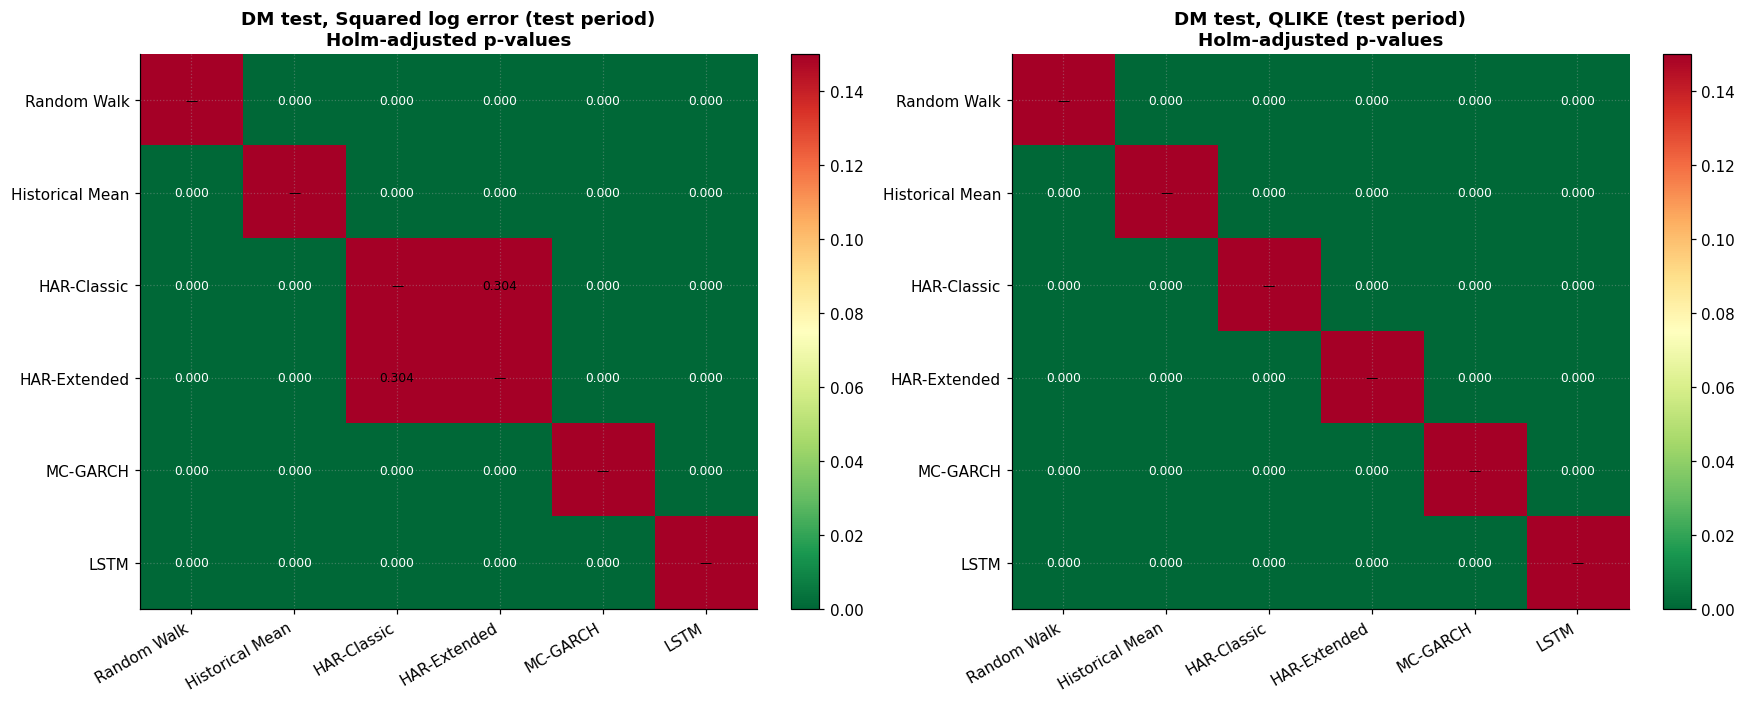

In [166]:
# 10.6 Compact "who beats whom" matrices (Holm-adjusted p-values, TEST period)

def p_matrix(tab):
    M = pd.DataFrame(np.nan, index=MAIN_MODELS, columns=MAIN_MODELS)
    for _, r in tab.iterrows():
        M.loc[r["Model 1"], r["Model 2"]] = r["p Holm"]; M.loc[r["Model 2"], r["Model 1"]] = r["p Holm"]
    return M

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, k in zip(axes, LOSS_NAMES):
    M = p_matrix(dm_test_tabs[k]); V = M.values.copy(); V[np.isnan(V)] = 1.0
    im = ax.imshow(V, cmap="RdYlGn_r", vmin=0, vmax=0.15, aspect="auto")
    ax.set_xticks(range(len(MAIN_MODELS))); ax.set_xticklabels(MAIN_MODELS, rotation=30, ha="right")
    ax.set_yticks(range(len(MAIN_MODELS))); ax.set_yticklabels(MAIN_MODELS)
    for i in range(len(MAIN_MODELS)):
        for j in range(len(MAIN_MODELS)):
            v = M.values[i, j]
            ax.text(j, i, "—" if np.isnan(v) else f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if (not np.isnan(v) and v < 0.07) else "black")
    ax.set_title(f"DM test, {LOSS_NAMES[k]} (test period)\nHolm-adjusted p-values", fontweight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figure_dm_pvalues.png", dpi=200); plt.show()

## 11 — VERIFICATION & APPENDIX

This section collects the consistency checks and the appendix figures. All models share one index of evaluation hours, so no alignment step is needed, and every forecast is a genuine out-of-sample forecast.

In [167]:
# 11.1 Consistency checks across all models

for per, idx, y in [("val", val_index, y_val_log), ("test", test_index, y_test_log)]:
    for m in ALL_MODELS:
        p = PRED[per][m]
        assert len(p) == len(idx) and np.isfinite(p).all(), f"{m}/{per}: forecast problem"
    assert df.loc[idx, "use"].all() and df.loc[idx, "eval_ok"].all()
print(f"  All {len(ALL_MODELS)} models have finite forecasts for exactly the same {len(val_index):,} validation and {len(test_index):,} test hours.")
print(f"  Test hours   : {test_index[0]} → {test_index[-1]}")
print(f"  Excluded in the test year range (zero RV or follows a zero-RV hour): {int(is_test.sum()) - len(test_index)}")

# Python vs R: fold boundaries and evaluation counts
r_wfv = pd.read_csv(os.path.join(MCGARCH_DIR, "mcgarch_wfv.csv"))
for f, (_, row) in zip(FOLDS, r_wfv.iterrows()):
    assert pd.Timestamp(row["from_utc"], tz="UTC") == f["start"], "Fold start differs from R"
    assert pd.Timestamp(row["to_utc"], tz="UTC") == f["end"], "Fold end differs from R"
    assert int(row["n_eval"]) == len(f["eval_idx"]), "Fold evaluation count differs from R"
print("  Python and R fold boundaries and evaluation counts are identical.")

  All 7 models have finite forecasts for exactly the same 17,514 validation and 17,539 test hours.
  Test hours   : 2024-01-01 00:00:00+00:00 → 2025-12-31 23:00:00+00:00
  Excluded in the test year range (zero RV or follows a zero-RV hour): 5
  Python and R fold boundaries and evaluation counts are identical.


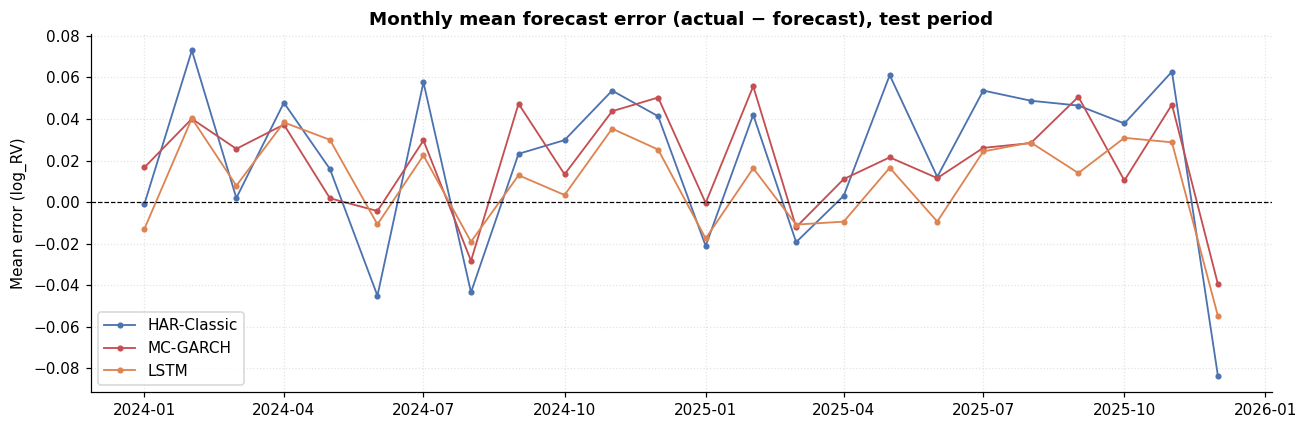

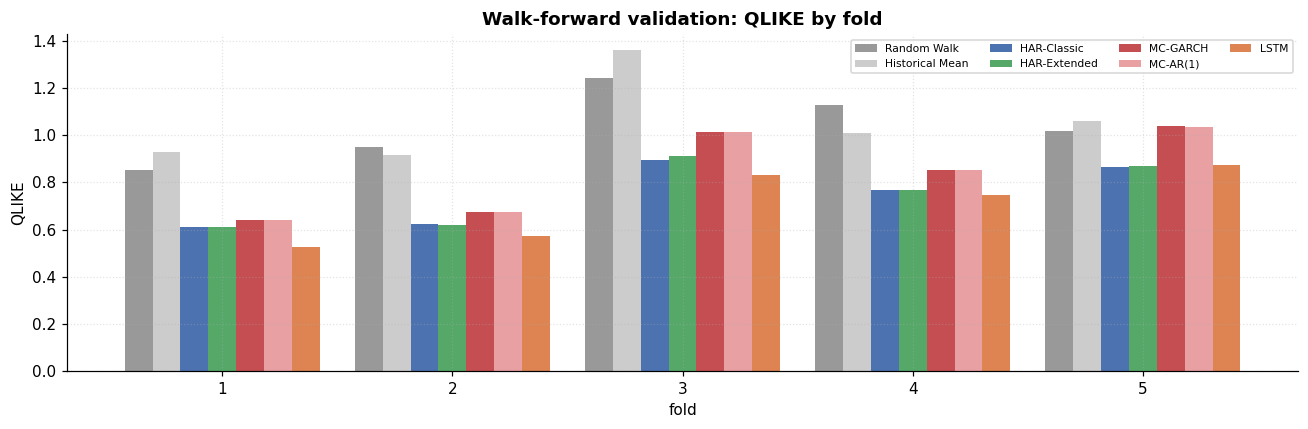

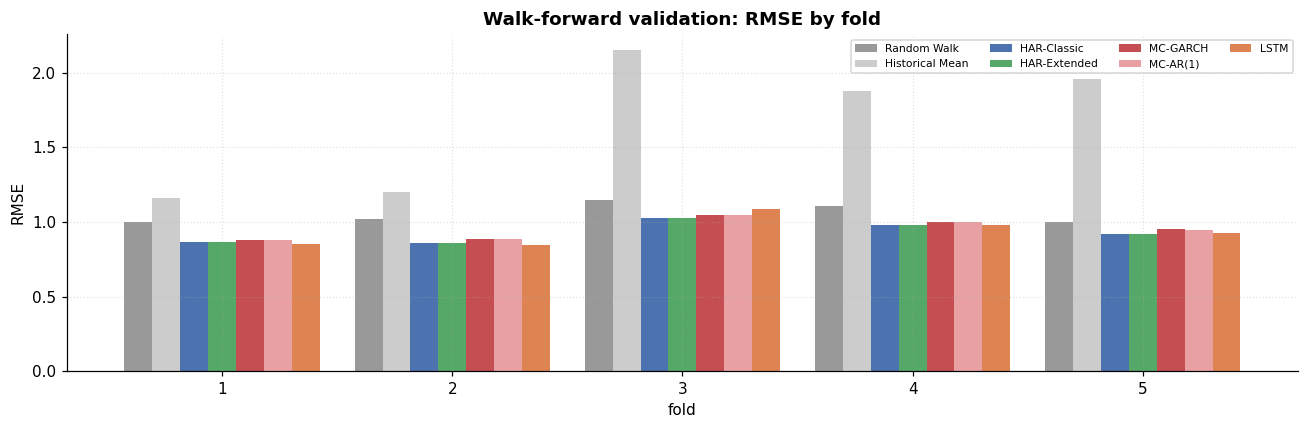

In [168]:
# 11.2 Appendix figures

# A1: monthly mean forecast error (actual - forecast) in the test period — shows regime-dependent bias
fig, ax = plt.subplots(figsize=(12, 4))
for m in ["HAR-Classic", "MC-GARCH", "LSTM"]:
    e = pd.Series(y_test_log - PRED["test"][m], index=test_index).resample("MS").mean()
    ax.plot(e.index, e.values, marker="o", ms=3, lw=1.2, color=MC[m], label=m)
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_title("Monthly mean forecast error (actual − forecast), test period", fontweight="bold")
ax.set_ylabel("Mean error (log_RV)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figure_A1_monthly_bias.png", dpi=200); plt.show()

# A2 / A3: walk-forward QLIKE and RMSE by fold, all models
for metric, tag in [("QLIKE", "A2"), ("RMSE", "A3")]:
    piv = fold_all.pivot(index="fold", columns="Model", values=metric)[ALL_MODELS]
    ax = piv.plot(kind="bar", figsize=(12, 4), rot=0, color=[MC.get(m, "#777") for m in ALL_MODELS], width=0.85)
    ax.set_title(f"Walk-forward validation: {metric} by fold", fontweight="bold"); ax.set_ylabel(metric)
    ax.legend(fontsize=7, ncol=4)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/figure_{tag}_wfv_{metric.lower()}.png", dpi=200); plt.show()

In [169]:
# 11.3 Save every forecast series and a run manifest

fc_val = pd.DataFrame({"datetime_utc": val_index, "fold": val_fold, "y_true_log": y_val_log, **{m: PRED["val"][m] for m in ALL_MODELS}})
fc_test = pd.DataFrame({"datetime_utc": test_index, "y_true_log": y_test_log, **{m: PRED["test"][m] for m in ALL_MODELS}})
fc_val.to_csv(f"{OUT_DIR}/all_forecasts_validation.csv", index=False)
fc_test.to_csv(f"{OUT_DIR}/all_forecasts_test.csv", index=False)

manifest = {"RETRAIN_LSTM": RETRAIN_LSTM, "LOOKBACK": LOOKBACK, "LSTM_PARAMS": LSTM_PARAMS, "LSTM_WFV_PARAMS": LSTM_WFV_PARAMS,
            "LSTM_FINAL_PARAMS": LSTM_FINAL_PARAMS, "DM_LAG_MAIN": DM_LAG_MAIN, "DM_LAGS_SENS": DM_LAGS_SENS, "HAC_LAGS_HAR": HAC_LAGS,
            "QLIKE_FLOOR": QLIKE_FLOOR, "n_val": int(len(val_index)), "n_test": int(len(test_index))}
with open(f"{OUT_DIR}/run_manifest.json", "w") as fh: json.dump(manifest, fh, indent=2, default=str)
print("  Saved:", sorted(os.path.basename(p) for p in glob.glob(f"{OUT_DIR}/*.csv") + glob.glob(f"{OUT_DIR}/*.json")))

  Saved: ['all_forecasts_test.csv', 'all_forecasts_validation.csv', 'run_manifest.json', 'table_descriptive_stats.csv', 'table_dm_mcgarch_vs_ar1.csv', 'table_dm_test.csv', 'table_dm_validation.csv', 'table_metrics_test.csv', 'table_metrics_validation.csv', 'table_vif.csv', 'table_wfv_folds.csv']
